### imports

In [19]:
import os
import json
import pickle
import numpy as np
import matplotlib.pyplot as plt

from typing import Union, List, Tuple, Any, Optional

from tqdm import tqdm
from sklearn.metrics import (confusion_matrix, roc_curve, auc, 
                             accuracy_score, classification_report)

import tensorflow as tf
import tensorflow_hub as hub
from tensorflow import keras
from tensorflow.keras.models import Model, Sequential, load_model
from tensorflow.keras.layers import (Lambda, Input, Conv2D, MaxPooling2D, 
                                     Concatenate, BatchNormalization, Dropout, 
                                     GlobalAveragePooling2D, Dense, Flatten, Activation)
from tensorflow.keras.applications import EfficientNetV2B1, VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.callbacks import (ModelCheckpoint, LearningRateScheduler, 
                                        TensorBoard, EarlyStopping)
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.preprocessing.image import ImageDataGenerator



### constants

In [24]:
ds_path = '//Users/flaviab/Downloads/data_breakhis'
save_path = '/Users/flaviab/Downloads/data_breakhis/training_models_checkpoints'

IMAGE_SIZE = (224, 340)
CROP_SIZE = (224, 224)
BATCH_SIZE = 128

### utils

In [22]:
def lr_schedule(epoch: int, lr_warmup_epochs: int = 25, lr_min: float = 1e-5, lr_max: float = 5e-5, lr_exp_decay: float = 0.8) -> float:
    
    """
    Função para calcular a taxa de aprendizado (learning rate) dinâmica baseada no número de épocas.
    
    Parâmetros:
    - epoch (int): A época atual.
    - lr_warmup_epochs (int): Número de épocas de aquecimento para aumentar o learning rate de forma linear.
    - lr_min (float): Valor mínimo do learning rate.
    - lr_max (float): Valor máximo do learning rate.
    - lr_exp_decay (float): Fator de decaimento exponencial para ajustar o learning rate após o aquecimento.

    Retorna:
    - lr (float): O valor do learning rate ajustado para a época atual.
    """
    
    lr_start = lr_min 
    if epoch < lr_warmup_epochs:
        lr = (lr_max - lr_start) / lr_warmup_epochs * epoch + lr_start
    else:
        lr = (lr_max - lr_min) * lr_exp_decay ** (epoch - lr_warmup_epochs) + lr_min
    return lr 


def load_latest_checkpoint(folder_path: str, model: Union[object, 'Model']) -> Union[object, 'Model']:
    
    """
    Função para carregar o último checkpoint salvo, se existir.
    
    Parâmetros:
    - folder_path (str): Caminho para o diretório que contém os checkpoints.
    - model (Model): Instância do modelo cujos pesos serão carregados.

    Retorna:
    - model (Model): O modelo com os pesos carregados do último checkpoint, se encontrado.
    """
    
    checkpoint_files = [f for f in os.listdir(folder_path) if f.endswith('.keras')]
    
    if checkpoint_files:
        checkpoint_files.sort(key=lambda x: os.path.getmtime(os.path.join(folder_path, x)))
        latest_checkpoint = os.path.join(folder_path, checkpoint_files[-1])
        print(f"Carregando checkpoint mais recente: {latest_checkpoint}")
        model.load_weights(latest_checkpoint)
    else:
        print("Nenhum checkpoint encontrado, iniciando novo treinamento.")
        
    return model

### Breakhis Dataset - data pre process

In [ ]:
def dataset(ds_path: str, image_size: Tuple[int, int] = IMAGE_SIZE, crop_size: Tuple[int, int] = CROP_SIZE, 
            batch_size: int = BATCH_SIZE, train_split: float = 0.7, val_split: float = 0.1, test_split: float = 0.2) -> Tuple[tf.data.Dataset, tf.data.Dataset, tf.data.Dataset]:
    """
    Função para carregar, dividir e aplicar augmentação a um dataset de imagens.

    Parâmetros:
    - ds_path (str): Caminho para o diretório do dataset.
    - image_size (Tuple[int, int]): Tamanho das imagens após redimensionamento.
    - crop_size (Tuple[int, int]): Tamanho das imagens após o recorte aleatório.
    - batch_size (int): Tamanho do lote (batch) a ser processado.
    - train_split (float): Proporção de amostras destinadas ao treinamento.
    - val_split (float): Proporção de amostras destinadas à validação.
    - test_split (float): Proporção de amostras destinadas ao teste.

    Retorna:
    - ds_train (tf.data.Dataset): Dataset de treinamento com augmentação e recorte aplicados.
    - ds_val (tf.data.Dataset): Dataset de validação com recorte aplicado.
    - ds_test (tf.data.Dataset): Dataset de teste com recorte aplicado.
    """
    
    ds = tf.keras.preprocessing.image_dataset_from_directory(
        ds_path, shuffle=True, label_mode='categorical',
        batch_size=batch_size, image_size=image_size)
    
    num_samples = tf.data.experimental.cardinality(ds).numpy()
    num_train_samples = int(num_samples * train_split)
    num_val_samples = int(num_samples * val_split)
    num_test_samples = num_samples - num_train_samples - num_val_samples
    
    ds_train = ds.take(num_train_samples)
    ds_val = ds.skip(num_train_samples).take(num_val_samples)
    ds_test = ds.skip(num_train_samples + num_val_samples).take(num_test_samples)

    # Definindo a augmentação de dados
    gen = tf.keras.preprocessing.image.ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        horizontal_flip=True,
        vertical_flip=True,
        shear_range=0.2,
        zoom_range=0.2)

    @tf.function
    
    def augment(images: tf.Tensor, labels: tf.Tensor) -> Tuple[tf.Tensor, tf.Tensor]:
        
        """
        Aplica augmentação nas imagens.

        Parâmetros:
        - images (tf.Tensor): Tensor com as imagens do batch.
        - labels (tf.Tensor): Tensor com os rótulos correspondentes.

        Retorna:
        - Augmented images (tf.Tensor) e labels (tf.Tensor).
        """
        
        aug_images = tf.map_fn(lambda image: tf.numpy_function(gen.random_transform,
                                                               [image],
                                                               tf.float32), 
                               images)
        aug_images = tf.ensure_shape(aug_images, images.shape)
        return aug_images, labels

    crop_layer = tf.keras.layers.RandomCrop(*crop_size)

    @tf.function
    
    def crop(images: tf.Tensor, labels: tf.Tensor) -> Tuple[tf.Tensor, tf.Tensor]:
        
        """
        Aplica recorte aleatório nas imagens.

        Parâmetros:
        - images (tf.Tensor): Tensor com as imagens do batch.
        - labels (tf.Tensor): Tensor com os rótulos correspondentes.

        Retorna:
        - Cropped images (tf.Tensor) e labels (tf.Tensor).
        """
        
        cropped_images = crop_layer(images, training=True)
        return cropped_images, labels

    ds_train = ds_train.map(augment, tf.data.experimental.AUTOTUNE)
    ds_train = ds_train.map(crop, tf.data.experimental.AUTOTUNE)
    ds_train = ds_train.prefetch(tf.data.experimental.AUTOTUNE)

    ds_val = ds_val.map(crop, tf.data.experimental.AUTOTUNE)
    ds_val = ds_val.prefetch(tf.data.experimental.AUTOTUNE)

    ds_test = ds_test.map(crop, tf.data.experimental.AUTOTUNE)
    ds_test = ds_test.prefetch(tf.data.experimental.AUTOTUNE)

    return ds_train, ds_val, ds_test

In [15]:
base_model = EfficientNetV2B1(include_top=False, input_shape=(224, 224, 3))

print("EfficientNetV2 Layers:")
for i, layer in enumerate(base_model.layers):
    print(f"Layer {i}: {layer.name}")

EfficientNetV2 Layers:
Layer 0: input_layer_4
Layer 1: rescaling_4
Layer 2: normalization_4
Layer 3: stem_conv
Layer 4: stem_bn
Layer 5: stem_activation
Layer 6: block1a_project_conv
Layer 7: block1a_project_bn
Layer 8: block1a_project_activation
Layer 9: block1b_project_conv
Layer 10: block1b_project_bn
Layer 11: block1b_project_activation
Layer 12: block1b_drop
Layer 13: block1b_add
Layer 14: block2a_expand_conv
Layer 15: block2a_expand_bn
Layer 16: block2a_expand_activation
Layer 17: block2a_project_conv
Layer 18: block2a_project_bn
Layer 19: block2b_expand_conv
Layer 20: block2b_expand_bn
Layer 21: block2b_expand_activation
Layer 22: block2b_project_conv
Layer 23: block2b_project_bn
Layer 24: block2b_drop
Layer 25: block2b_add
Layer 26: block2c_expand_conv
Layer 27: block2c_expand_bn
Layer 28: block2c_expand_activation
Layer 29: block2c_project_conv
Layer 30: block2c_project_bn
Layer 31: block2c_drop
Layer 32: block2c_add
Layer 33: block3a_expand_conv
Layer 34: block3a_expand_bn
La

### model

In [16]:
def naive_inception_module(layer_in: tf.Tensor, f1: int, f2: int, f3: int) -> tf.Tensor:
    
    """
    Implementação de um módulo Inception simplificado (Naive Inception).
    
    Parâmetros:
    - layer_in (tf.Tensor): Tensor de entrada da camada anterior.
    - f1 (int): Número de filtros para a convolução 1x1.
    - f2 (int): Número de filtros para a convolução 3x3.
    - f3 (int): Número de filtros para a convolução 5x5.

    Retorna:
    - layer_out (tf.Tensor): Tensor de saída após concatenar as diferentes convoluções e pooling.
    """
    # 1x1 conv
    conv1 = Conv2D(f1, (1, 1), padding='same', activation='relu')(layer_in)
    # 3x3 conv
    conv3 = Conv2D(f2, (3, 3), padding='same', activation='relu')(layer_in)
    # 5x5 conv
    conv5 = Conv2D(f3, (5, 5), padding='same', activation='relu')(layer_in)
    # 3x3 max pooling
    pool = MaxPooling2D((3, 3), strides=(1, 1), padding='same')(layer_in)
    # Concatenar filtros
    layer_out = Concatenate()([conv1, conv3, conv5, pool])
    
    return layer_out

def efficientnetv2_builder(finetune: bool = False, model: Union[Model, None] = None, 
                           trainable_blocks: Union[List[str], None] = None, 
                           print_trainable: bool = False) -> Model:
    
    """
    Constrói um modelo com base no EfficientNetV2B1. Permite tanto o treinamento do zero quanto o fine-tuning.

    Parâmetros:
    - finetune (bool): Se True, faz fine-tuning em camadas específicas do EfficientNetV2B1.
    - model (Model, optional): Modelo preexistente para aplicar o fine-tuning, se necessário.
    - trainable_blocks (List[str], optional): Lista de blocos de camadas a serem destravadas para treino no fine-tuning.
    - print_trainable (bool): Se True, imprime quais camadas estão sendo treinadas durante o fine-tuning.

    Retorna:
    - model (Model): O modelo construído, pronto para treinamento ou fine-tuning.
    """
    
    base_model = EfficientNetV2B1(include_top=False, input_shape=(224, 224, 3))
    shallow_efficientnet = tf.keras.Model(inputs=base_model.input, 
                                          outputs=base_model.get_layer('block3c_add').output, 
                                          name='efficientnetv2b1_shallow')
    
    if not finetune:
        shallow_efficientnet.trainable = False

        image_input = tf.keras.Input((224, 224, 3), name='Image_Input')
        out = shallow_efficientnet(image_input)
        out = naive_inception_module(out, 64, 128, 32)
        bn1 = tf.keras.layers.BatchNormalization(name='BN')(out)
        f = Flatten()(bn1)
        dropout = Dropout(0.4, name='Dropout')(f)
        dense = Dense(2, activation='softmax', name='Predictions')(dropout)

        model = tf.keras.Model(inputs=image_input, outputs=dense)
        
    else:
        model.get_layer('efficientnetv2b1_shallow').trainable = False
        for layer in model.get_layer('efficientnetv2b1_shallow').layers:
            for block_name in trainable_blocks:
                if layer.name.startswith(block_name):
                    layer.trainable = True 
            if print_trainable:
                print(layer.name, layer.trainable) 

    return model


def model_dataset_epoch(model: Model, train_set: tf.data.Dataset, val_set: tf.data.Dataset, 
                        test_set: tf.data.Dataset, epoch: int, folder_path: str, 
                        strategy: str = "train", plot_title: str = "") -> Tuple[tf.keras.callbacks.History, Model]:
    
    """
    Função para treinar e/ou aplicar fine-tuning no modelo, salvar checkpoints e avaliar o modelo.

    Parâmetros:
    - model (Model): O modelo que será treinado ou afinado.
    - train_set (tf.data.Dataset): Conjunto de dados de treinamento.
    - val_set (tf.data.Dataset): Conjunto de dados de validação.
    - test_set (tf.data.Dataset): Conjunto de dados de teste.
    - epoch (int): Número de épocas para o treinamento.
    - folder_path (str): Caminho da pasta onde os checkpoints serão salvos.
    - strategy (str): "train" para treinamento normal ou "finetune" para ajuste fino.
    - plot_title (str): Título para a avaliação do modelo pós-treinamento.

    Retorna:
    - train_history (tf.keras.callbacks.History): Histórico de treinamento do modelo.
    - model (Model): O melhor modelo treinado.
    """
    
    callbacks = [
        ModelCheckpoint(
            monitor='val_accuracy',
            filepath=os.path.join(folder_path, "model-weights.{epoch:02d}-{val_accuracy:.6f}.keras"),
            verbose=1,
            save_best_only=True,
            save_weights_only=False  
        ),
        tf.keras.callbacks.TensorBoard(log_dir=os.path.join(folder_path, 'tb_logdir/'))
    ]

    if strategy == "train":
        opt = tf.keras.optimizers.Adam(learning_rate=0.001)
        model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
        
        init_epochs = epoch
        train_history = model.fit(train_set, epochs=init_epochs, validation_data=val_set, verbose=1, callbacks=callbacks)

        files = os.listdir(folder_path)
        files.sort(key=lambda x: os.path.getmtime(os.path.join(folder_path, x)))
        last_file = files[-1]
        model_path = os.path.join(folder_path, last_file)
        print('Best model path: ', model_path)
        best_model = tf.keras.models.load_model(model_path)

        best_model.evaluate(test_set)
        eval_model(best_model, test_set, title=plot_title)

    elif strategy == "finetune":
        model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

        # Fine-tuning
        cbs = [
            tf.keras.callbacks.LearningRateScheduler(lr_schedule, verbose=True),
            ModelCheckpoint(
                monitor='val_accuracy',
                filepath=os.path.join(folder_path, "model-weights.{epoch:02d}-{val_accuracy:.6f}.keras"),
                verbose=1,
                save_best_only=True,
                save_weights_only=False
            ),
            tf.keras.callbacks.TensorBoard(log_dir=os.path.join(folder_path, 'tb_logdir/'))
        ]

        train_history = model.fit(train_set, epochs=epoch + epoch,
                                  validation_data=val_set,
                                  initial_epoch=epoch,
                                  callbacks=cbs,
                                  verbose=1)

        files = os.listdir(folder_path)
        files.sort(key=lambda x: os.path.getmtime(os.path.join(folder_path, x)))
        last_file = files[-1]
        model_path = os.path.join(folder_path, last_file)
        print('Best model path: ', model_path)
        best_model = tf.keras.models.load_model(model_path)

        best_model.evaluate(test_set)
        eval_model(best_model, test_set, title=plot_title)

    return train_history, model

### evaluate model

In [17]:
def plot_train_history(train_history: tf.keras.callbacks.History, train_history2: Optional[tf.keras.callbacks.History] = None, title: str = "") -> None:
    
    """
    Função para plotar o histórico de treinamento e validação de um ou dois treinamentos consecutivos.

    Parâmetros:
    - train_history (tf.keras.callbacks.History): Histórico do primeiro treinamento.
    - train_history2 (Optional[tf.keras.callbacks.History]): Histórico do segundo treinamento (ex. fine-tuning).
    - title (str): Título do gráfico.

    Retorna:
    - None: Apenas exibe os gráficos.
    """
    
    if train_history2 is not None:
        acc = train_history.history['accuracy'] + train_history2.history['accuracy']
        val_acc = train_history.history['val_accuracy'] + train_history2.history['val_accuracy']
        loss = train_history.history['loss'] + train_history2.history['loss']
        val_loss = train_history.history['val_loss'] + train_history2.history['val_loss']
        init_epochs = len(train_history.history['accuracy'])
    else:
        acc = train_history.history['accuracy']
        val_acc = train_history.history['val_accuracy']
        loss = train_history.history['loss']
        val_loss = train_history.history['val_loss'] 

    fig = plt.figure(figsize=(16, 4))
    fig.patch.set_alpha(0.5)

    plt.subplot(1, 2, 1)
    plt.plot(acc)
    plt.plot(val_acc)
    if train_history2 is not None:
        plt.plot([init_epochs - 1, init_epochs - 1], plt.ylim())
    plt.legend(['Training Accuracy', 'Validation Accuracy', 'Start Fine Tuning'],
               loc='lower right')
    plt.ylabel('Accuracy')
    plt.title(title)

    plt.subplot(1, 2, 2)
    plt.plot(loss)
    plt.plot(val_loss)
    if train_history2 is not None:
        plt.plot([init_epochs - 1, init_epochs - 1], plt.ylim())
    plt.legend(['Training Loss', 'Validation Loss', 'Start Fine Tuning'],
               loc='upper right')
    plt.ylabel('Cross Entropy')
    plt.xlabel('Epochs')
    plt.title(title) 
    plt.show()


def plot_confusion_matrix_manual(y_true: np.ndarray, y_pred: np.ndarray, normalize: bool = False, title: str = "Confusion Matrix") -> None:
    
    """
    Função para plotar a matriz de confusão.

    Parâmetros:
    - y_true (np.ndarray): Valores reais dos rótulos.
    - y_pred (np.ndarray): Valores previstos dos rótulos.
    - normalize (bool): Se True, normaliza a matriz de confusão.
    - title (str): Título do gráfico.

    Retorna:
    - None: Apenas exibe o gráfico.
    """
    
    cm = confusion_matrix(y_true, y_pred, normalize='true' if normalize else None)
    fig, ax = plt.subplots(figsize=(8, 6))
    cax = ax.matshow(cm, cmap=plt.cm.Blues)
    fig.colorbar(cax)
    
    ax.set_xticks(np.arange(len(np.unique(y_true))))
    ax.set_yticks(np.arange(len(np.unique(y_true))))
    ax.set_xticklabels(np.unique(y_true))
    ax.set_yticklabels(np.unique(y_true))
    
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(title)
    plt.show()


def plot_roc_manual(y_true: np.ndarray, y_probas: np.ndarray, title: str = "ROC Curve") -> None:
    
    """
    Função para plotar a curva ROC e calcular a AUC.

    Parâmetros:
    - y_true (np.ndarray): Valores reais dos rótulos.
    - y_probas (np.ndarray): Probabilidades previstas para a classe positiva.
    - title (str): Título do gráfico.

    Retorna:
    - None: Apenas exibe o gráfico.
    """
    
    fpr, tpr, _ = roc_curve(y_true, y_probas)
    roc_auc = auc(fpr, tpr)
    
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()


def eval_model(model: tf.keras.Model, test_loader: tf.data.Dataset, title: str) -> None:
    
    """
    Avalia o modelo no conjunto de teste e plota métricas de avaliação.

    Parâmetros:
    - model (tf.keras.Model): Modelo treinado a ser avaliado.
    - test_loader (tf.data.Dataset): Conjunto de dados de teste.
    - title (str): Título para as avaliações plotadas.

    Retorna:
    - None: Exibe os resultados e gráficos de avaliação.
    """
    
    y_true, y_pred = [], []
    for images, labels in test_loader:
        preds = model.predict(images)
        y_true.append(labels.numpy())
        y_pred.append(preds)

    y_true, y_pred = np.concatenate(y_true), np.concatenate(y_pred)
    y_probas = y_pred  
    y_true, y_pred = np.argmax(y_true, axis=1), np.argmax(y_pred, axis=1)

    print('Accuracy: ', accuracy_score(y_true, y_pred))
    print(classification_report(y_true, y_pred))

    plot_confusion_matrix_manual(y_true, y_pred, title=f"{title} (Confusion Matrix)")
    plot_confusion_matrix_manual(y_true, y_pred, normalize=True, title=f"{title} (Normalized Confusion Matrix)")

    plot_roc_manual(y_true, y_probas[:, 1], title=f"{title} (ROC Curve)")

Resolutions:   0%|                                        | 0/4 [00:00<?, ?it/s]

Found 1995 files belonging to 2 classes.


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 28, 28,    │          0 │ conv2d_18[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_19[0][0],  │
│                     │                   │            │ conv2d_20[0][0],  │
│                     │                   │            │ max_pooling2d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_6[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_6 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 857,410 (3.27 MB)

 Trainable params: 524,034 (2.00 MB)

 Non-trainable params: 333,376 (1.27 MB)

Carregando checkpoint mais recente: /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v01/40X/model-weights.03-0.906250.keras
Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 869ms/step - accuracy: 0.8008 - loss: 3.0563
Epoch 1: val_accuracy improved from -inf to 0.78906, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v01/40X/model-weights.01-0.789062.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.8028 - loss: 3.0215 - val_accuracy: 0.7891 - val_loss: 5.1524
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 894ms/step - accuracy: 0.8256 - loss: 2.1153
Epoch 2: val_accuracy improved from 0.78906 to 0.89062, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v01/40X/model-weights.02-0.890625.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.8265 - loss: 2.1213 - val_accuracy: 0.8906 - val_loss: 2.1683
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━

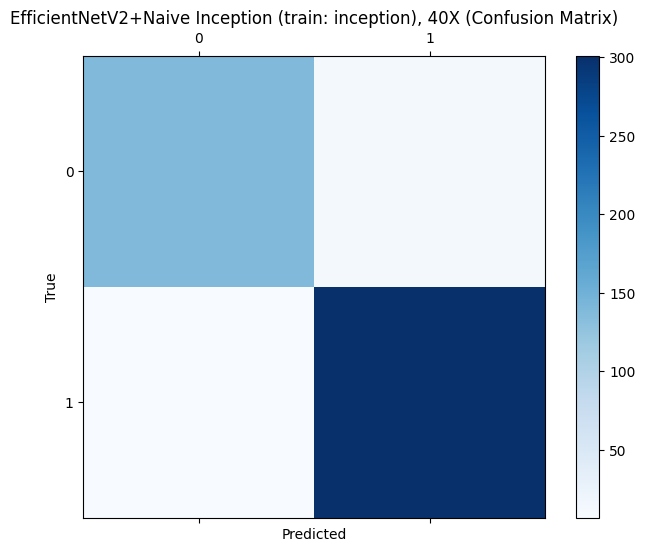

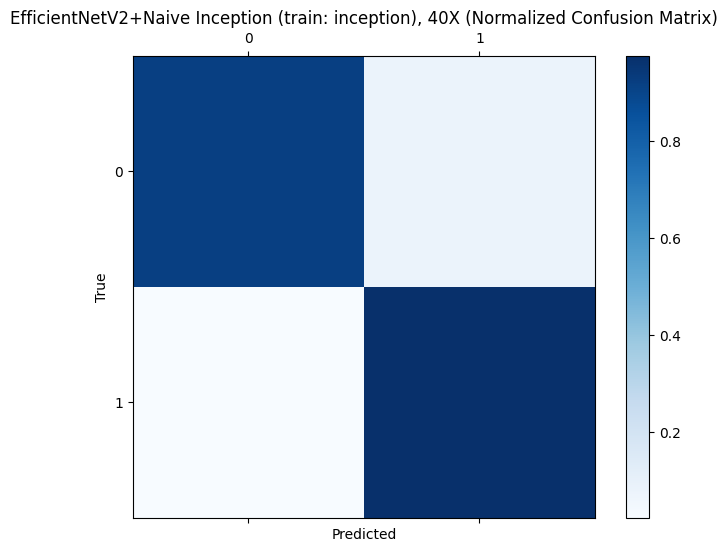

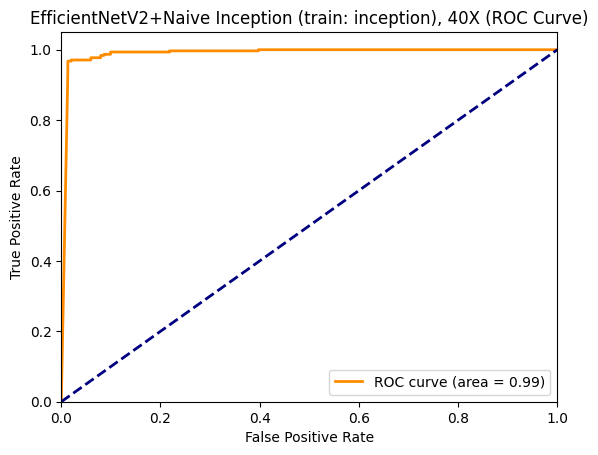

input_layer_11 False
rescaling_11 False
normalization_11 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv False
block1a_project_bn False
block1a_project_activation False
block1b_project_conv False
block1b_project_bn False
block1b_project_activation False
block1b_drop False
block1b_add False
block2a_expand_conv False
block2a_expand_bn False
block2a_expand_activation False
block2a_project_conv False
block2a_project_bn False
block2b_expand_conv False
block2b_expand_bn False
block2b_expand_activation False
block2b_project_conv False
block2b_project_bn False
block2b_drop False
block2b_add False
block2c_expand_conv False
block2c_expand_bn False
block2c_expand_activation False
block2c_project_conv False
block2c_project_bn False
block2c_drop False
block2c_add False
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 28, 28,    │          0 │ conv2d_18[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_19[0][0],  │
│                     │                   │            │ conv2d_20[0][0],  │
│                     │                   │            │ max_pooling2d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_6[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_6 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,905,480 (7.27 MB)

 Trainable params: 752,674 (2.87 MB)

 Non-trainable params: 104,736 (409.12 KB)

 Optimizer params: 1,048,070 (4.00 MB)

Carregando checkpoint mais recente: /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v02/40X/model-weights.78-0.992188.keras

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100


/Users/flaviab/csi_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:713: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 58 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9437 - loss: 0.9126
Epoch 51: val_accuracy improved from -inf to 0.99219, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v02/40X/model-weights.51-0.992188.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.9439 - loss: 0.9142 - val_accuracy: 0.9922 - val_loss: 0.1948 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9471 - loss: 0.7641
Epoch 52: val_accuracy did not improve from 0.99219
11/11 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.9466 - loss: 0.7652 - val_accuracy: 0.9609 - val_loss: 0.2425 - learning_rate: 1.0000e-05

Epoch 53: LearningRateScheduler setting learning rate to 1.0000365376224684e-05.
Epoch 53/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9470 - loss: 0.6506
Epoch 53: val_accuracy did not improve from 0.99219
11/11

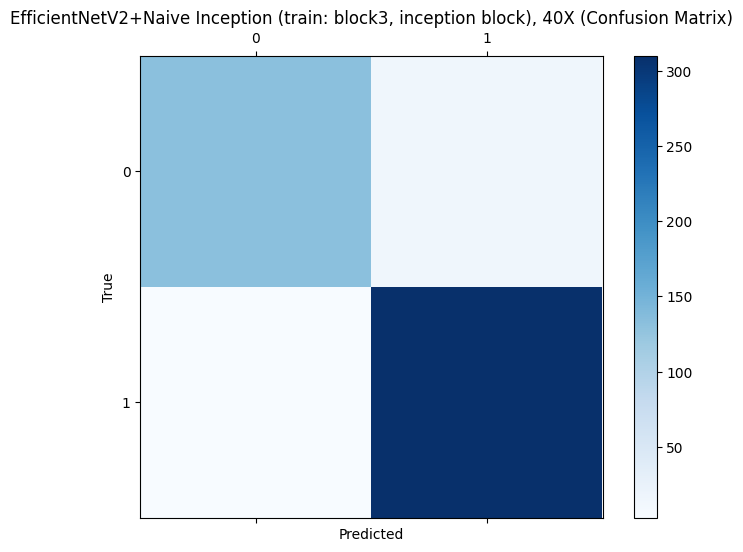

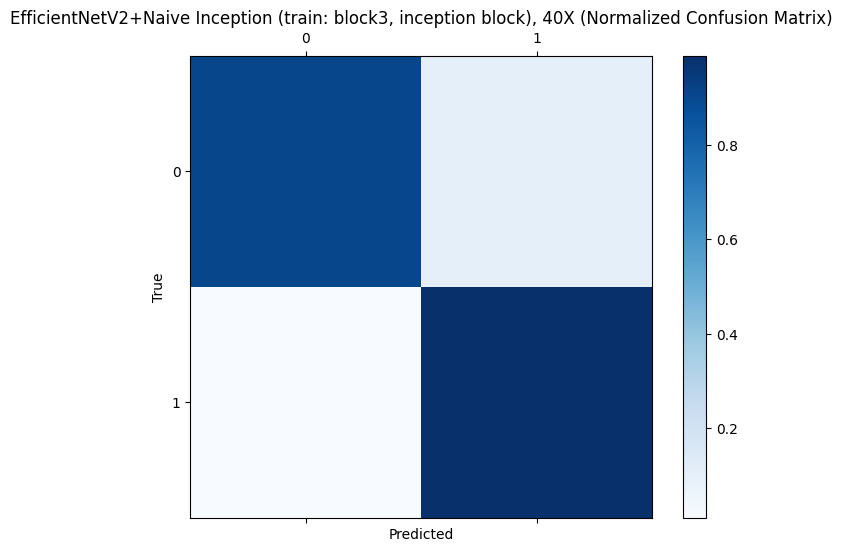

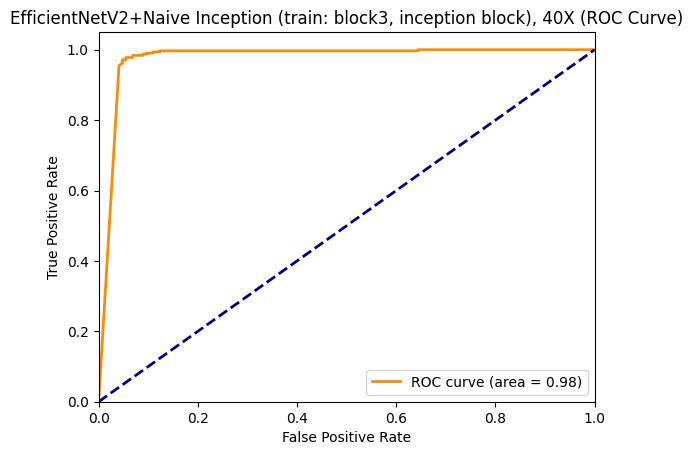

input_layer_11 False
rescaling_11 False
normalization_11 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv False
block1a_project_bn False
block1a_project_activation False
block1b_project_conv False
block1b_project_bn False
block1b_project_activation False
block1b_drop False
block1b_add False
block2a_expand_conv True
block2a_expand_bn True
block2a_expand_activation True
block2a_project_conv True
block2a_project_bn True
block2b_expand_conv True
block2b_expand_bn True
block2b_expand_activation True
block2b_project_conv True
block2b_project_bn True
block2b_drop True
block2b_add True
block2c_expand_conv True
block2c_expand_bn True
block2c_expand_activation True
block2c_project_conv True
block2c_project_bn True
block2c_drop True
block2c_add True
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation True
block3b_proje

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 28, 28,    │          0 │ conv2d_18[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_19[0][0],  │
│                     │                   │            │ conv2d_20[0][0],  │
│                     │                   │            │ max_pooling2d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_6[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_6 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,362,760 (9.01 MB)

 Trainable params: 846,690 (3.23 MB)

 Non-trainable params: 10,720 (41.88 KB)

 Optimizer params: 1,505,350 (5.74 MB)

Carregando checkpoint mais recente: /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v03/40X/model-weights.85-1.000000.keras

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100


/Users/flaviab/csi_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:713: UserWarning: Skipping variable loading for optimizer 'adam', because it has 58 variables whereas the saved optimizer has 94 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9339 - loss: 0.9888
Epoch 51: val_accuracy improved from -inf to 0.96875, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v03/40X/model-weights.51-0.968750.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.9345 - loss: 0.9687 - val_accuracy: 0.9688 - val_loss: 0.5312 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9427 - loss: 0.8497
Epoch 52: val_accuracy did not improve from 0.96875
11/11 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.9431 - loss: 0.8470 - val_accuracy: 0.9688 - val_loss: 0.7719 - learning_rate: 1.0000e-05

Epoch 53: LearningRateScheduler setting learning rate to 1.0000365376224684e-05.
Epoch 53/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9504 - loss: 0.6060
Epoch 53: val_accuracy did not improve from 0.96875
11/11

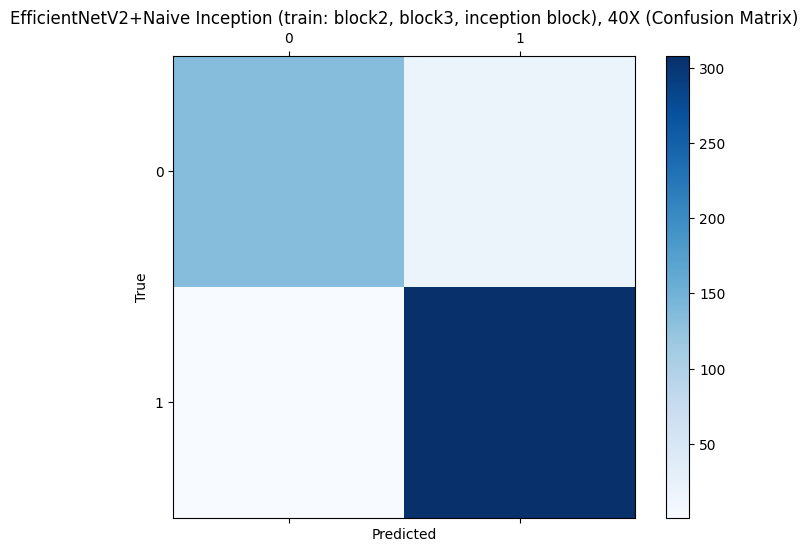

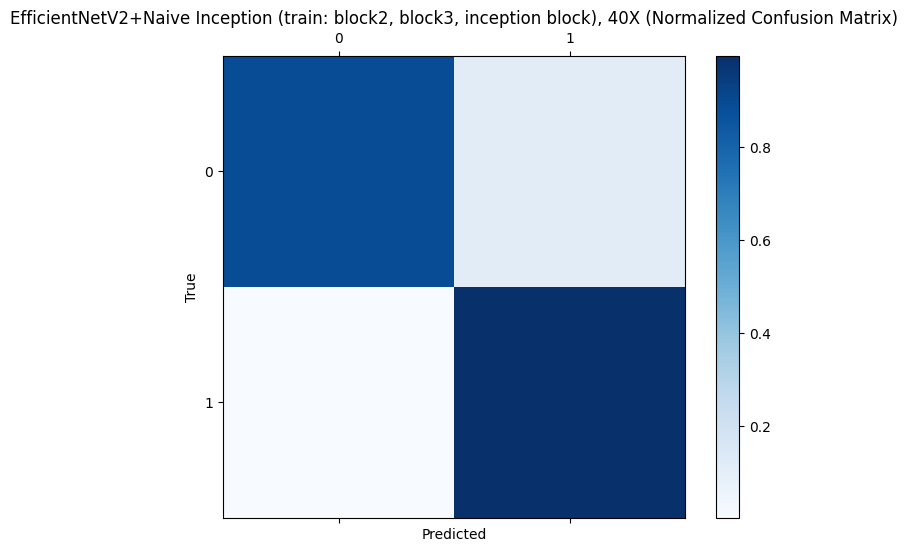

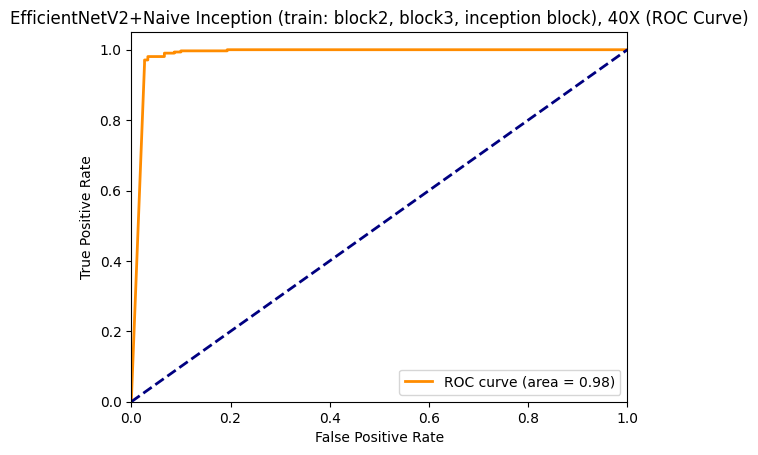

input_layer_11 False
rescaling_11 False
normalization_11 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv True
block1a_project_bn True
block1a_project_activation True
block1b_project_conv True
block1b_project_bn True
block1b_project_activation True
block1b_drop True
block1b_add True
block2a_expand_conv True
block2a_expand_bn True
block2a_expand_activation True
block2a_project_conv True
block2a_project_bn True
block2b_expand_conv True
block2b_expand_bn True
block2b_expand_activation True
block2b_project_conv True
block2b_project_bn True
block2b_drop True
block2b_add True
block2c_expand_conv True
block2c_expand_bn True
block2c_expand_activation True
block2c_project_conv True
block2c_project_bn True
block2c_drop True
block2c_add True
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation True
block3b_project_conv 

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 28, 28,    │          0 │ conv2d_18[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_19[0][0],  │
│                     │                   │            │ conv2d_20[0][0],  │
│                     │                   │            │ max_pooling2d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_6[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_6 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,550,792 (9.73 MB)

 Trainable params: 853,666 (3.26 MB)

 Non-trainable params: 3,744 (14.62 KB)

 Optimizer params: 1,693,382 (6.46 MB)

Carregando checkpoint mais recente: /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v04/40X/model-weights.98-1.000000.keras

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100


/Users/flaviab/csi_env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:713: UserWarning: Skipping variable loading for optimizer 'adam', because it has 94 variables whereas the saved optimizer has 106 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9549 - loss: 0.5264
Epoch 51: val_accuracy improved from -inf to 0.98438, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v04/40X/model-weights.51-0.984375.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9544 - loss: 0.5312 - val_accuracy: 0.9844 - val_loss: 0.1106 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9492 - loss: 0.7826
Epoch 52: val_accuracy did not improve from 0.98438
11/11 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.9495 - loss: 0.7701 - val_accuracy: 0.9688 - val_loss: 0.7544 - learning_rate: 1.0000e-05

Epoch 53: LearningRateScheduler setting learning rate to 1.0000365376224684e-05.
Epoch 53/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9605 - loss: 0.4408
Epoch 53: val_accuracy improved from 0.98438 to 0.99219, 

2024-10-04 19:54:53.135154: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


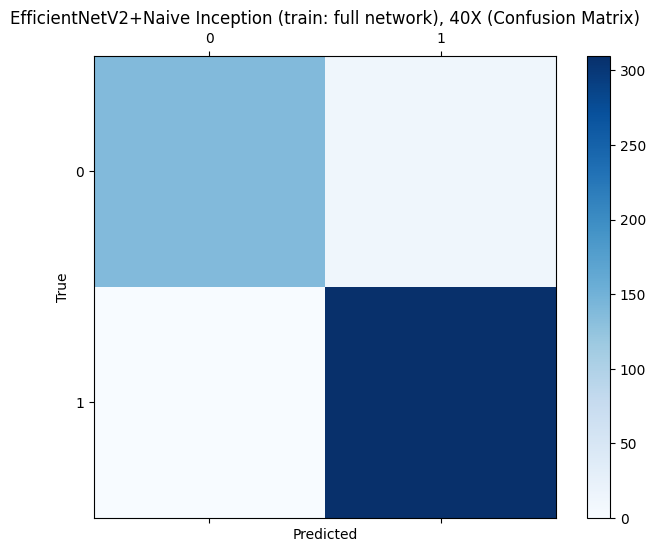

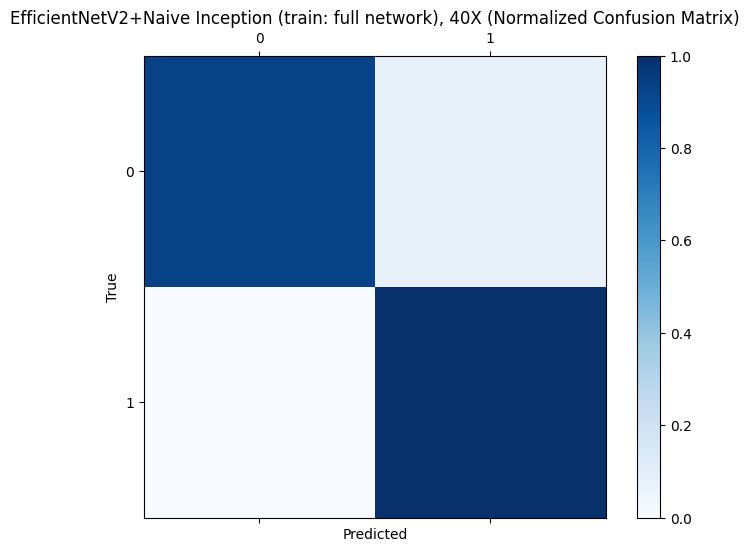

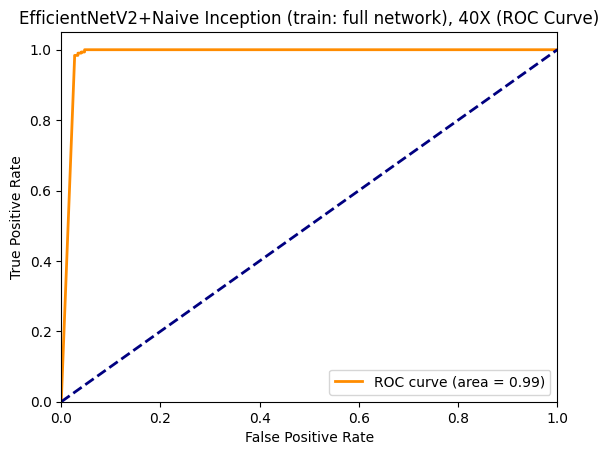

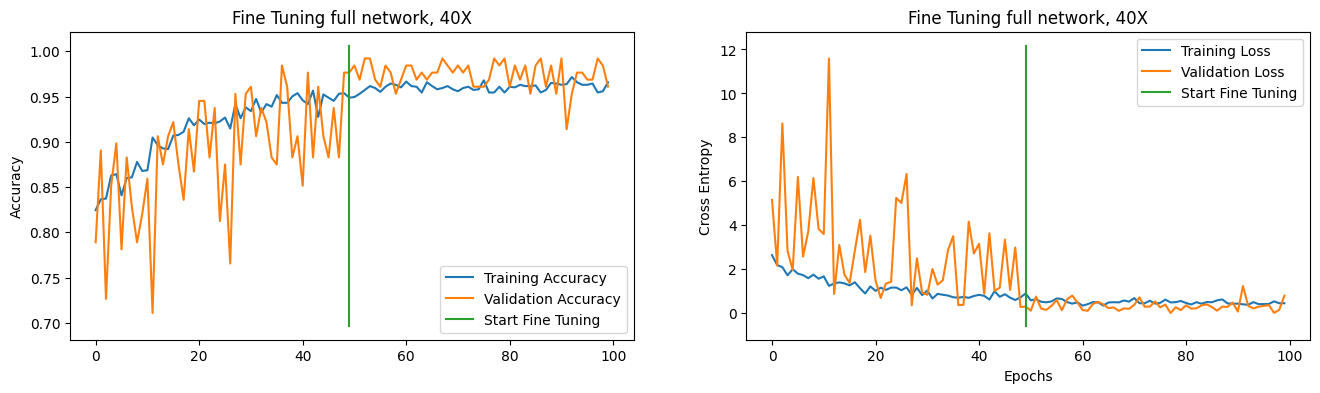

Resolutions:  25%|██████▌                   | 1/4 [1:27:20<4:22:02, 5240.97s/it]

Found 2038 files belonging to 2 classes.


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 28, 28,    │          0 │ conv2d_21[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_22[0][0],  │
│                     │                   │            │ conv2d_23[0][0],  │
│                     │                   │            │ max_pooling2d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_7[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_7 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 857,410 (3.27 MB)

 Trainable params: 524,034 (2.00 MB)

 Non-trainable params: 333,376 (1.27 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.
Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 870ms/step - accuracy: 0.7175 - loss: 2.7742
Epoch 1: val_accuracy improved from -inf to 0.73438, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v01/100X/model-weights.01-0.734375.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.7225 - loss: 2.8019 - val_accuracy: 0.7344 - val_loss: 37.8426
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - accuracy: 0.8457 - loss: 2.5411
Epoch 2: val_accuracy did not improve from 0.73438
11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.8446 - loss: 2.5508 - val_accuracy: 0.7109 - val_loss: 51.6043
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 855ms/step - accuracy: 0.8157 - loss: 2.1835
Epoch 3: val_accuracy did not improve from 0.73438
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.8169 - loss: 2.1759 - val_accuracy: 0.6484 - val_loss: 43.5287
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━

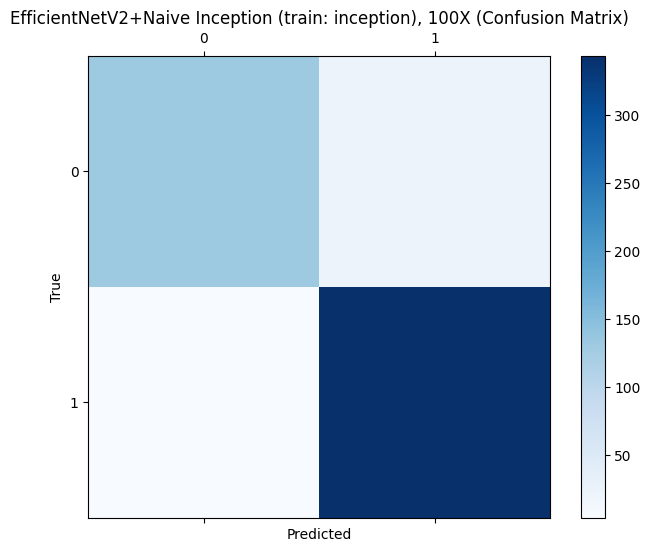

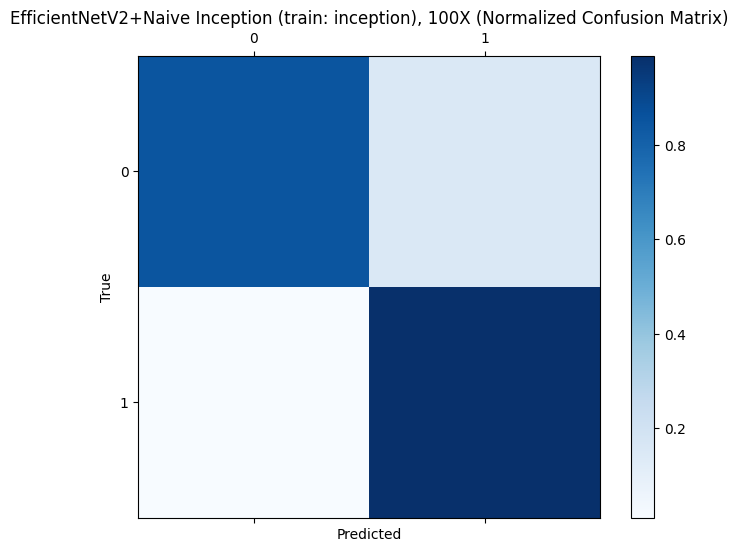

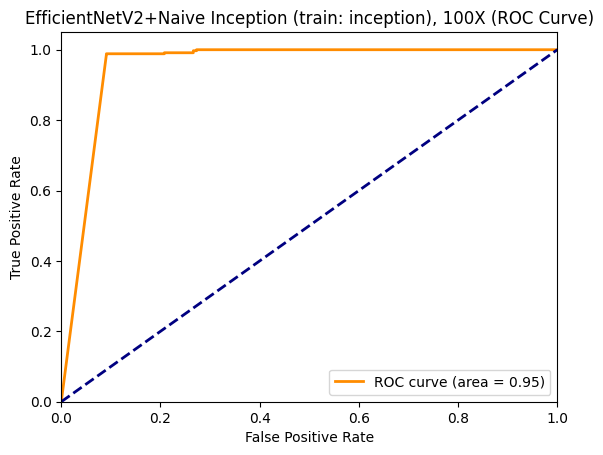

input_layer_15 False
rescaling_15 False
normalization_15 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv False
block1a_project_bn False
block1a_project_activation False
block1b_project_conv False
block1b_project_bn False
block1b_project_activation False
block1b_drop False
block1b_add False
block2a_expand_conv False
block2a_expand_bn False
block2a_expand_activation False
block2a_project_conv False
block2a_project_bn False
block2b_expand_conv False
block2b_expand_bn False
block2b_expand_activation False
block2b_project_conv False
block2b_project_bn False
block2b_drop False
block2b_add False
block2c_expand_conv False
block2c_expand_bn False
block2c_expand_activation False
block2c_project_conv False
block2c_project_bn False
block2c_drop False
block2c_add False
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 28, 28,    │          0 │ conv2d_21[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_22[0][0],  │
│                     │                   │            │ conv2d_23[0][0],  │
│                     │                   │            │ max_pooling2d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_7[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_7 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,905,480 (7.27 MB)

 Trainable params: 752,674 (2.87 MB)

 Non-trainable params: 104,736 (409.12 KB)

 Optimizer params: 1,048,070 (4.00 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8165 - loss: 3.9698
Epoch 51: val_accuracy improved from -inf to 0.67969, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v02/100X/model-weights.51-0.679688.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.8178 - loss: 3.9541 - val_accuracy: 0.6797 - val_loss: 10.3675 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8481 - loss: 3.2128
Epoch 52: val_accuracy did not improve from 0.67969
11/11 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.8487 - loss: 3.2054 - val_accuracy: 0.5781 - val_loss: 20.6212 - learning_rate: 1.0000e-05

Epoch 53: LearningRateScheduler setting learning rate to 1.00003653

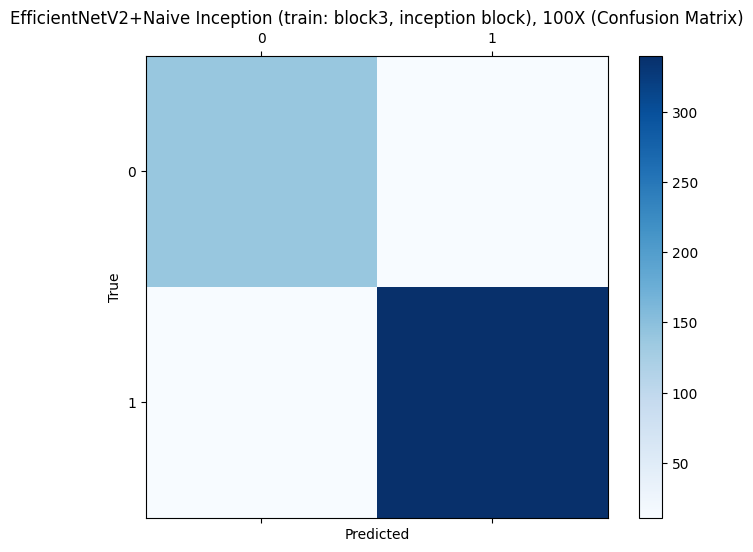

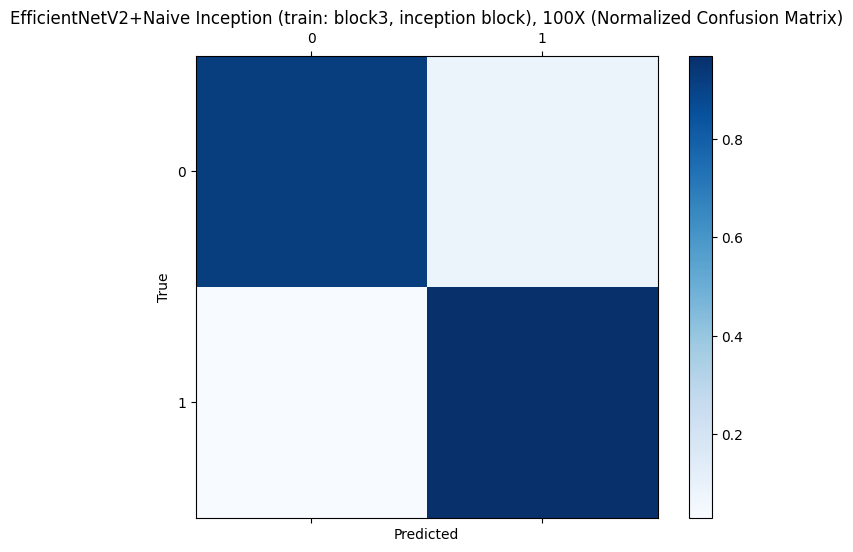

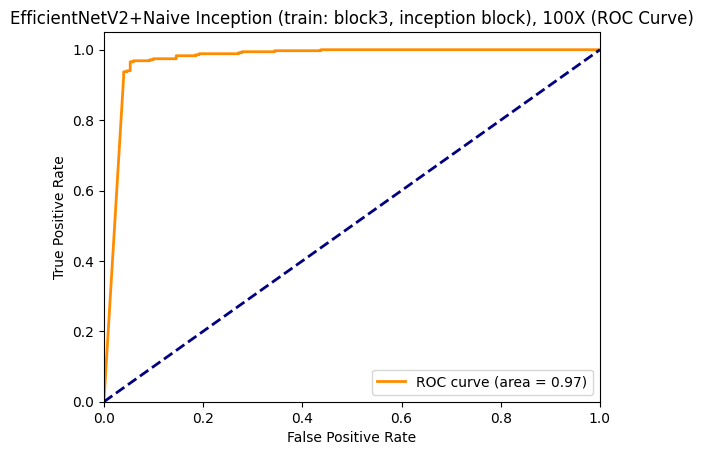

input_layer_15 False
rescaling_15 False
normalization_15 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv False
block1a_project_bn False
block1a_project_activation False
block1b_project_conv False
block1b_project_bn False
block1b_project_activation False
block1b_drop False
block1b_add False
block2a_expand_conv True
block2a_expand_bn True
block2a_expand_activation True
block2a_project_conv True
block2a_project_bn True
block2b_expand_conv True
block2b_expand_bn True
block2b_expand_activation True
block2b_project_conv True
block2b_project_bn True
block2b_drop True
block2b_add True
block2c_expand_conv True
block2c_expand_bn True
block2c_expand_activation True
block2c_project_conv True
block2c_project_bn True
block2c_drop True
block2c_add True
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation True
block3b_proje

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 28, 28,    │          0 │ conv2d_21[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_22[0][0],  │
│                     │                   │            │ conv2d_23[0][0],  │
│                     │                   │            │ max_pooling2d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_7[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_7 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,362,760 (9.01 MB)

 Trainable params: 846,690 (3.23 MB)

 Non-trainable params: 10,720 (41.88 KB)

 Optimizer params: 1,505,350 (5.74 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8153 - loss: 6.2300
Epoch 51: val_accuracy improved from -inf to 0.97656, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v03/100X/model-weights.51-0.976562.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8161 - loss: 6.1642 - val_accuracy: 0.9766 - val_loss: 0.4487 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8456 - loss: 4.8337
Epoch 52: val_accuracy did not improve from 0.97656
11/11 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.8460 - loss: 4.8275 - val_accuracy: 0.9531 - val_loss: 0.3402 - learning_rate: 1.0000e-05

Epoch 53: LearningRateScheduler setting learning rate to 1.0000365376

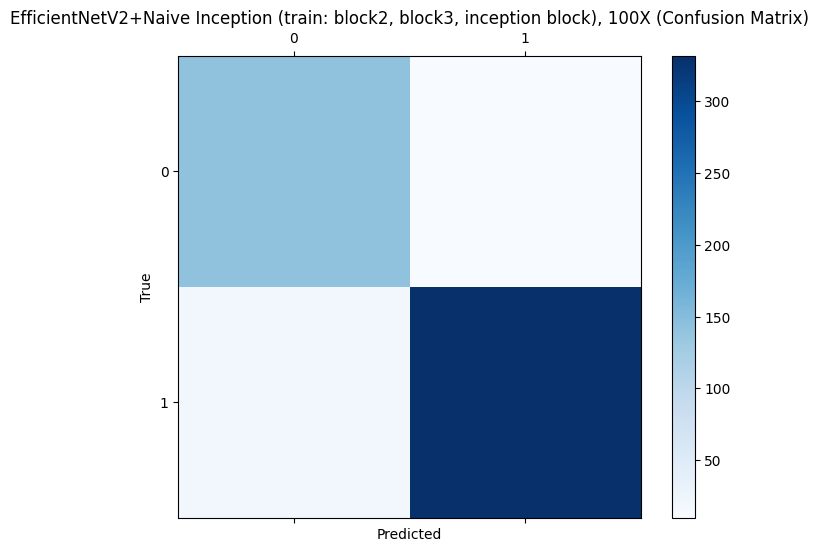

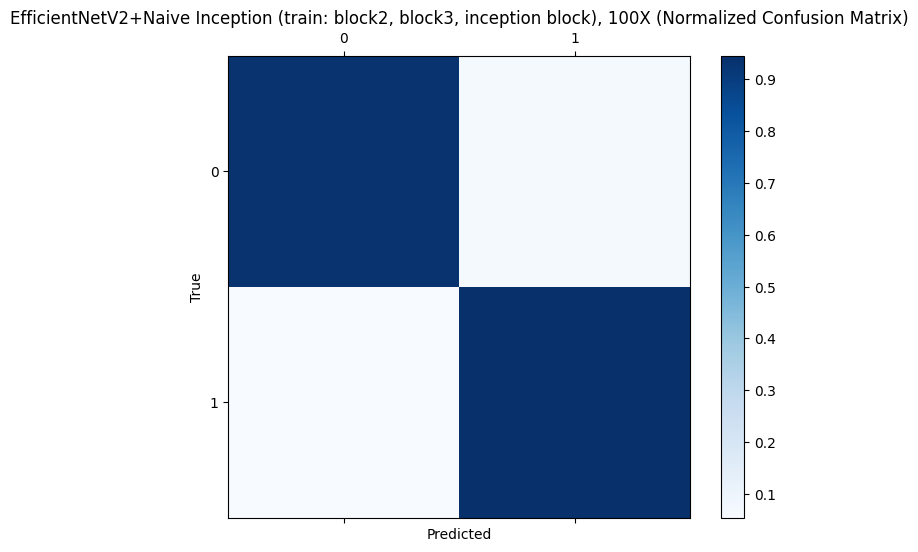

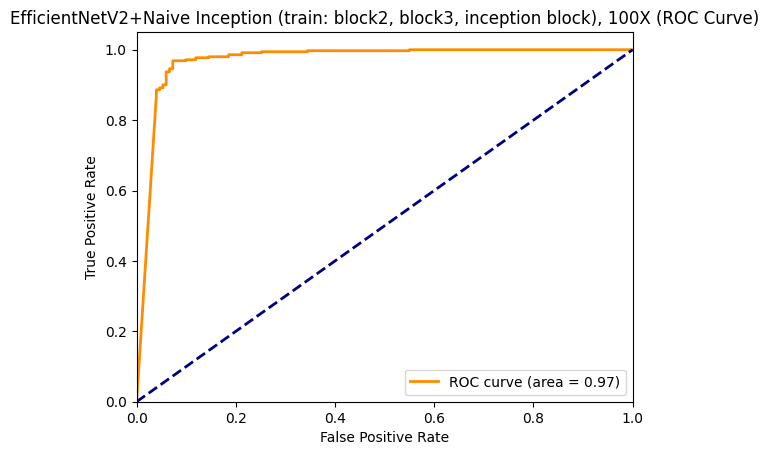

input_layer_15 False
rescaling_15 False
normalization_15 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv True
block1a_project_bn True
block1a_project_activation True
block1b_project_conv True
block1b_project_bn True
block1b_project_activation True
block1b_drop True
block1b_add True
block2a_expand_conv True
block2a_expand_bn True
block2a_expand_activation True
block2a_project_conv True
block2a_project_bn True
block2b_expand_conv True
block2b_expand_bn True
block2b_expand_activation True
block2b_project_conv True
block2b_project_bn True
block2b_drop True
block2b_add True
block2c_expand_conv True
block2c_expand_bn True
block2c_expand_activation True
block2c_project_conv True
block2c_project_bn True
block2c_drop True
block2c_add True
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation True
block3b_project_conv 

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 28, 28,    │          0 │ conv2d_21[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_22[0][0],  │
│                     │                   │            │ conv2d_23[0][0],  │
│                     │                   │            │ max_pooling2d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_7[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_7 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,550,792 (9.73 MB)

 Trainable params: 853,666 (3.26 MB)

 Non-trainable params: 3,744 (14.62 KB)

 Optimizer params: 1,693,382 (6.46 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9464 - loss: 0.8709
Epoch 51: val_accuracy improved from -inf to 0.95312, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v04/100X/model-weights.51-0.953125.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.9463 - loss: 0.8850 - val_accuracy: 0.9531 - val_loss: 1.2404 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9390 - loss: 0.9864
Epoch 52: val_accuracy improved from 0.95312 to 0.96094, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v04/100X/model-weights.52-0.960938.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.9389 - lo

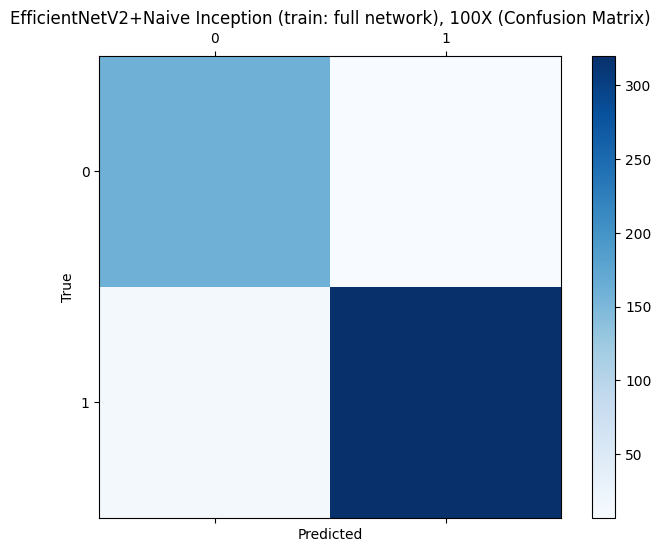

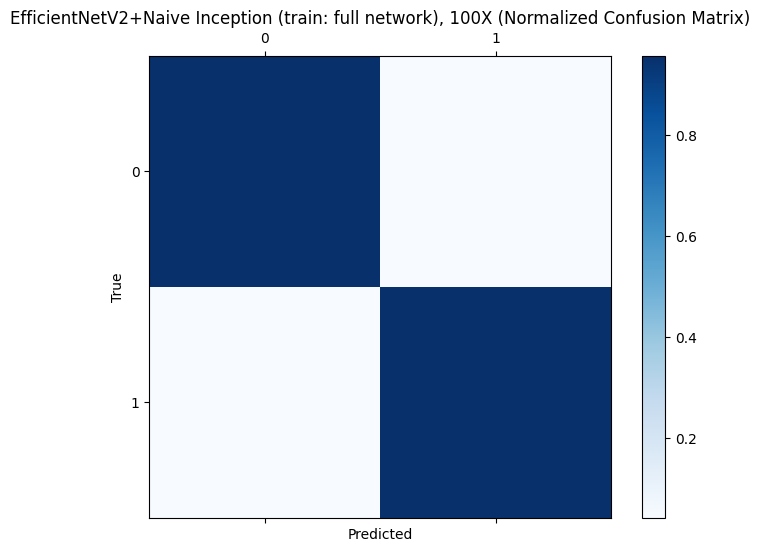

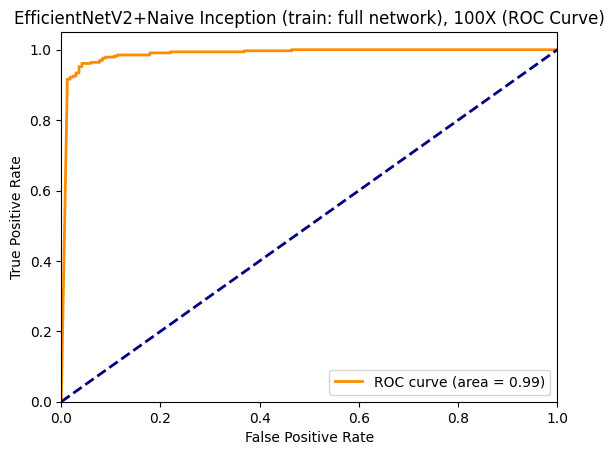

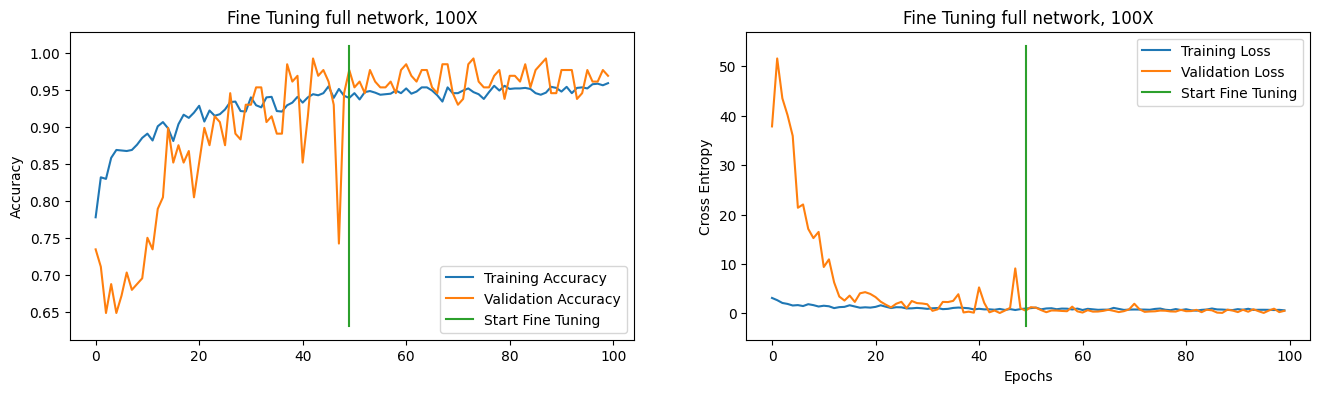

Resolutions:  50%|█████████████             | 2/4 [2:53:58<2:53:51, 5215.57s/it]

Found 2013 files belonging to 2 classes.


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 28, 28,    │          0 │ conv2d_24[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_25[0][0],  │
│                     │                   │            │ conv2d_26[0][0],  │
│                     │                   │            │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_8[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 857,410 (3.27 MB)

 Trainable params: 524,034 (2.00 MB)

 Non-trainable params: 333,376 (1.27 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.
Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 838ms/step - accuracy: 0.7154 - loss: 4.2987
Epoch 1: val_accuracy improved from -inf to 0.70312, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v01/200X/model-weights.01-0.703125.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.7218 - loss: 4.2960 - val_accuracy: 0.7031 - val_loss: 22.3825
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 858ms/step - accuracy: 0.8497 - loss: 2.1323
Epoch 2: val_accuracy improved from 0.70312 to 0.75000, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v01/200X/model-weights.02-0.750000.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.8495 - loss: 2.1383 - val_accuracy: 0.7500 - val_loss: 10.7739
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 841ms/step - accuracy: 0.8161 - loss: 1.8956
Epoch 3: val_accuracy improved from 0.75000 to 0.81

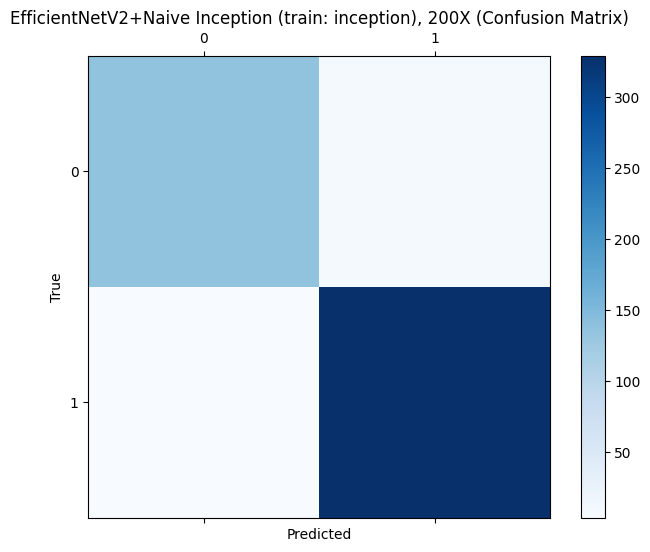

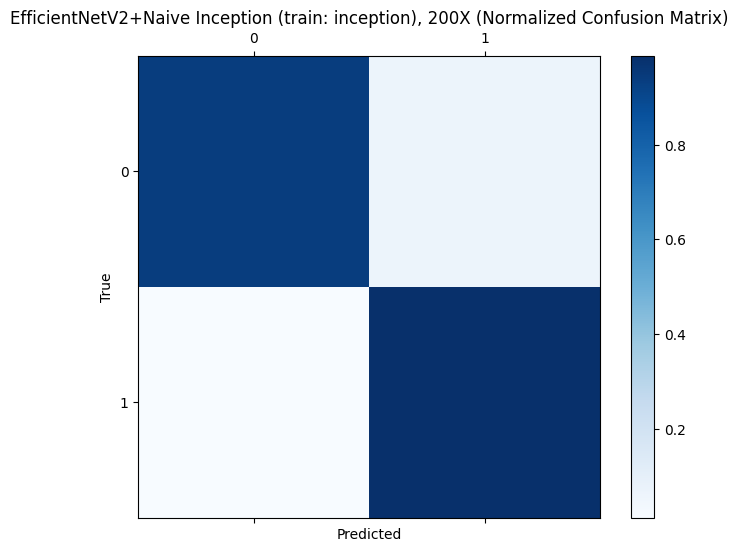

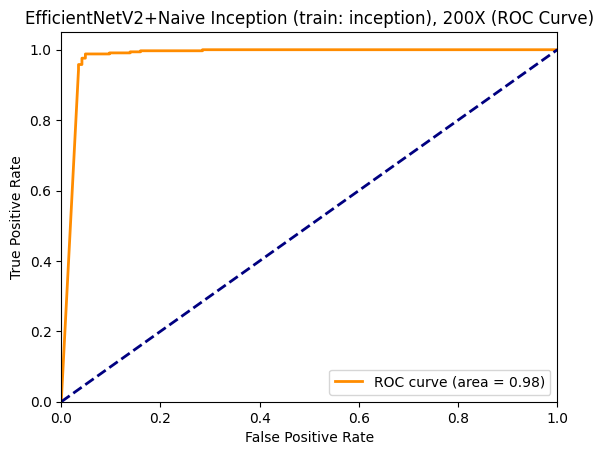

input_layer_19 False
rescaling_19 False
normalization_19 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv False
block1a_project_bn False
block1a_project_activation False
block1b_project_conv False
block1b_project_bn False
block1b_project_activation False
block1b_drop False
block1b_add False
block2a_expand_conv False
block2a_expand_bn False
block2a_expand_activation False
block2a_project_conv False
block2a_project_bn False
block2b_expand_conv False
block2b_expand_bn False
block2b_expand_activation False
block2b_project_conv False
block2b_project_bn False
block2b_drop False
block2b_add False
block2c_expand_conv False
block2c_expand_bn False
block2c_expand_activation False
block2c_project_conv False
block2c_project_bn False
block2c_drop False
block2c_add False
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 28, 28,    │          0 │ conv2d_24[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_25[0][0],  │
│                     │                   │            │ conv2d_26[0][0],  │
│                     │                   │            │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_8[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,905,480 (7.27 MB)

 Trainable params: 752,674 (2.87 MB)

 Non-trainable params: 104,736 (409.12 KB)

 Optimizer params: 1,048,070 (4.00 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8867 - loss: 2.9079
Epoch 51: val_accuracy improved from -inf to 0.67188, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v02/200X/model-weights.51-0.671875.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.8868 - loss: 2.9003 - val_accuracy: 0.6719 - val_loss: 13.1560 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8741 - loss: 3.5108
Epoch 52: val_accuracy did not improve from 0.67188
11/11 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.8753 - loss: 3.4728 - val_accuracy: 0.4531 - val_loss: 34.1047 - learning_rate: 1.0000e-05

Epoch 53: LearningRateScheduler setting learning rate to 1.00003653

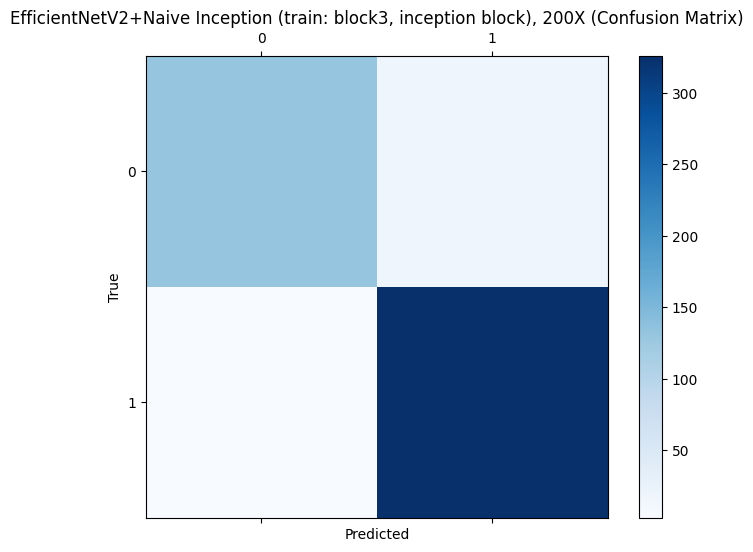

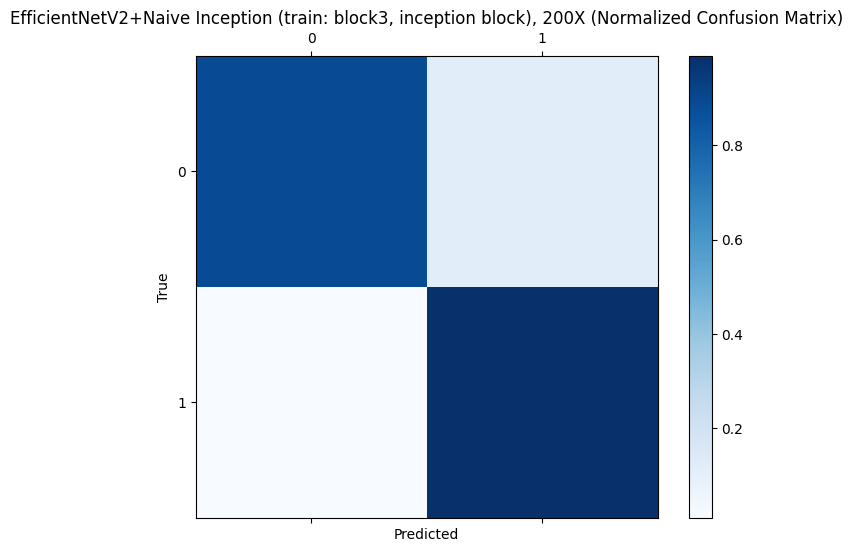

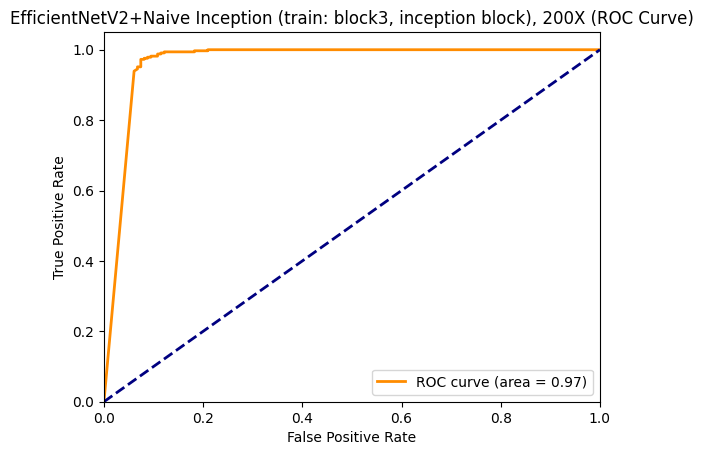

input_layer_19 False
rescaling_19 False
normalization_19 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv False
block1a_project_bn False
block1a_project_activation False
block1b_project_conv False
block1b_project_bn False
block1b_project_activation False
block1b_drop False
block1b_add False
block2a_expand_conv True
block2a_expand_bn True
block2a_expand_activation True
block2a_project_conv True
block2a_project_bn True
block2b_expand_conv True
block2b_expand_bn True
block2b_expand_activation True
block2b_project_conv True
block2b_project_bn True
block2b_drop True
block2b_add True
block2c_expand_conv True
block2c_expand_bn True
block2c_expand_activation True
block2c_project_conv True
block2c_project_bn True
block2c_drop True
block2c_add True
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation True
block3b_proje

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 28, 28,    │          0 │ conv2d_24[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_25[0][0],  │
│                     │                   │            │ conv2d_26[0][0],  │
│                     │                   │            │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_8[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,362,760 (9.01 MB)

 Trainable params: 846,690 (3.23 MB)

 Non-trainable params: 10,720 (41.88 KB)

 Optimizer params: 1,505,350 (5.74 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9027 - loss: 2.0378
Epoch 51: val_accuracy improved from -inf to 0.95312, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v03/200X/model-weights.51-0.953125.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 36s 3s/step - accuracy: 0.9026 - loss: 2.0261 - val_accuracy: 0.9531 - val_loss: 0.7463 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8967 - loss: 2.1635
Epoch 52: val_accuracy improved from 0.95312 to 0.96094, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v03/200X/model-weights.52-0.960938.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - accuracy: 0.8974 - lo

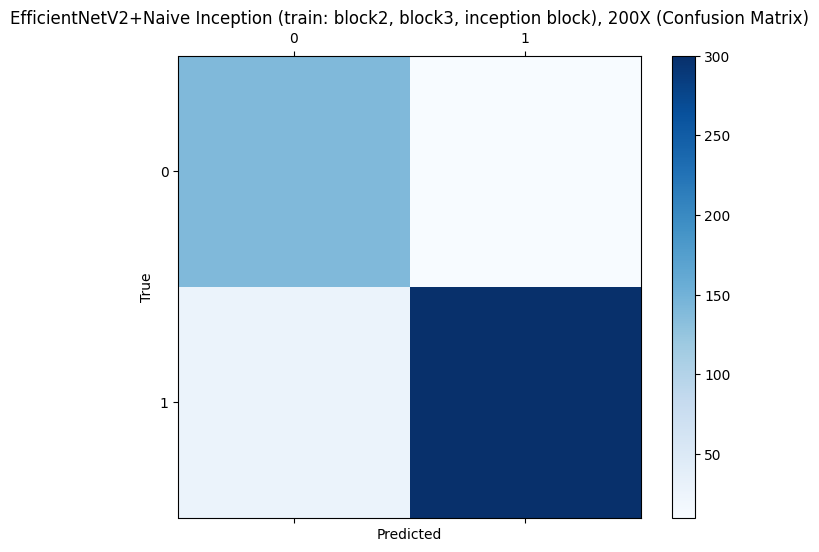

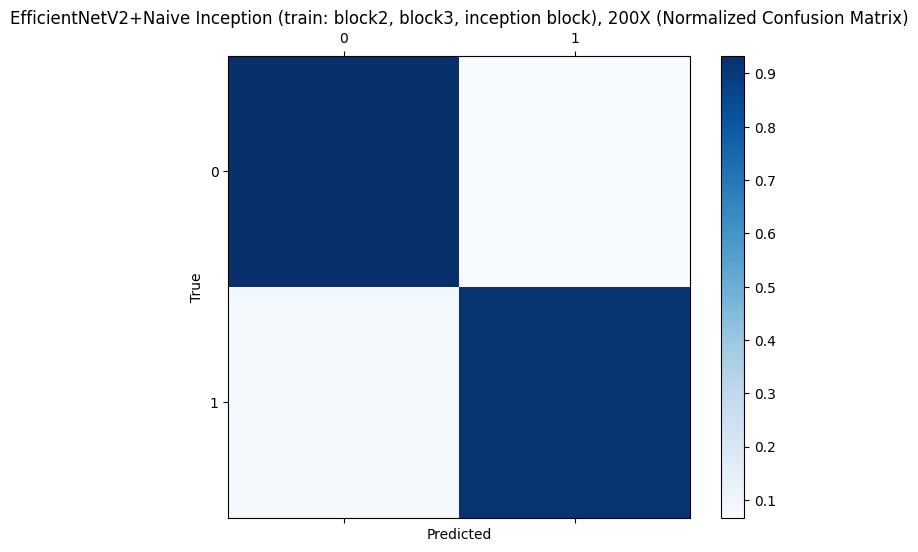

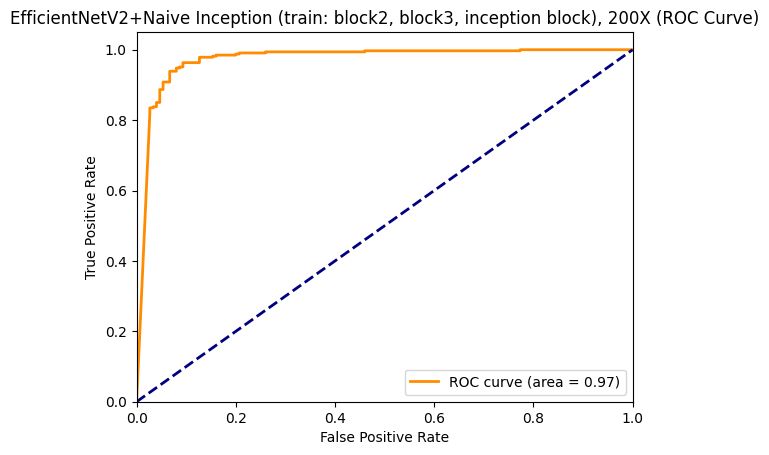

input_layer_19 False
rescaling_19 False
normalization_19 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv True
block1a_project_bn True
block1a_project_activation True
block1b_project_conv True
block1b_project_bn True
block1b_project_activation True
block1b_drop True
block1b_add True
block2a_expand_conv True
block2a_expand_bn True
block2a_expand_activation True
block2a_project_conv True
block2a_project_bn True
block2b_expand_conv True
block2b_expand_bn True
block2b_expand_activation True
block2b_project_conv True
block2b_project_bn True
block2b_drop True
block2b_add True
block2c_expand_conv True
block2c_expand_bn True
block2c_expand_activation True
block2c_project_conv True
block2c_project_bn True
block2c_drop True
block2c_add True
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation True
block3b_project_conv 

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 28, 28,    │          0 │ conv2d_24[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_25[0][0],  │
│                     │                   │            │ conv2d_26[0][0],  │
│                     │                   │            │ max_pooling2d_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_8[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,550,792 (9.73 MB)

 Trainable params: 853,666 (3.26 MB)

 Non-trainable params: 3,744 (14.62 KB)

 Optimizer params: 1,693,382 (6.46 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9404 - loss: 1.0605
Epoch 51: val_accuracy improved from -inf to 0.93750, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v04/200X/model-weights.51-0.937500.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.9404 - loss: 1.0588 - val_accuracy: 0.9375 - val_loss: 0.7151 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9372 - loss: 1.1943
Epoch 52: val_accuracy improved from 0.93750 to 0.96094, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v04/200X/model-weights.52-0.960938.keras
11/11 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.9372 - lo

2024-10-04 22:47:37.631125: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


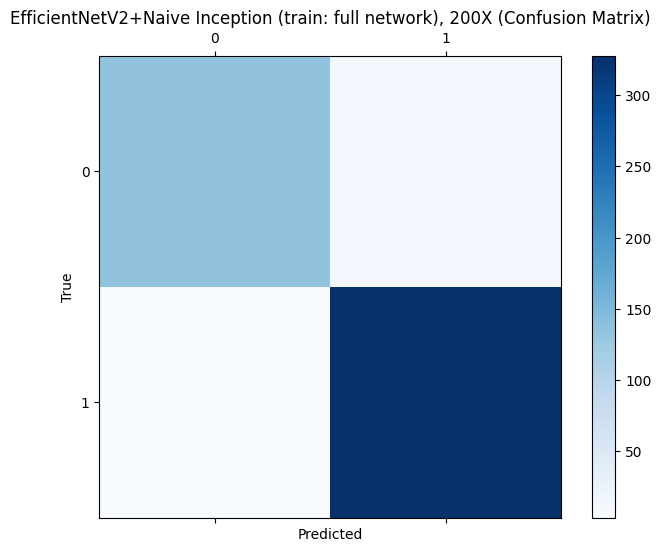

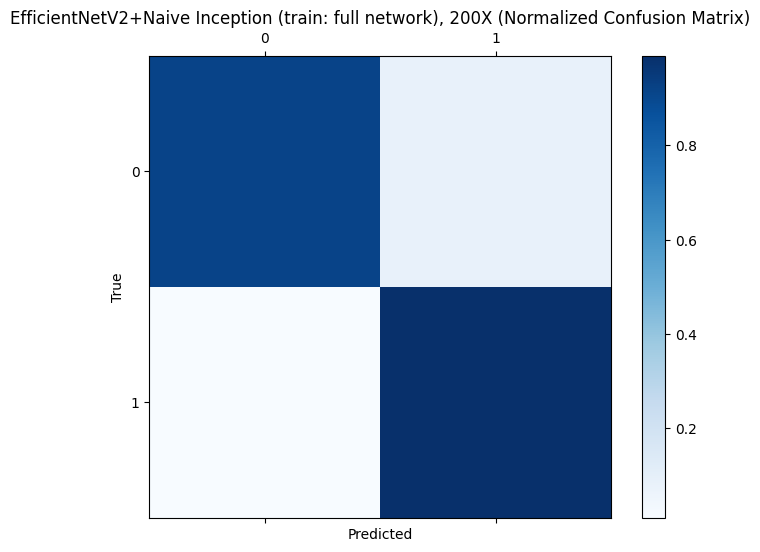

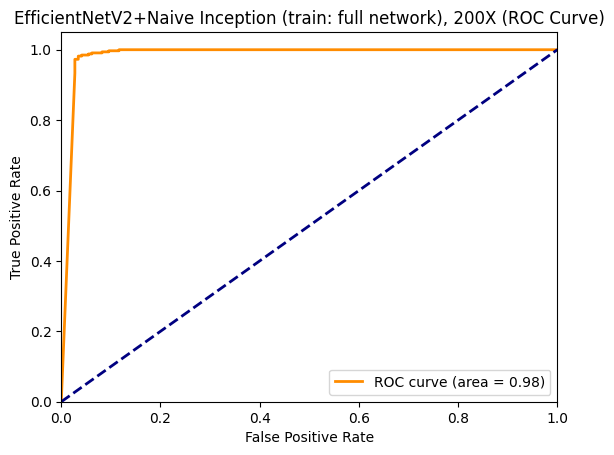

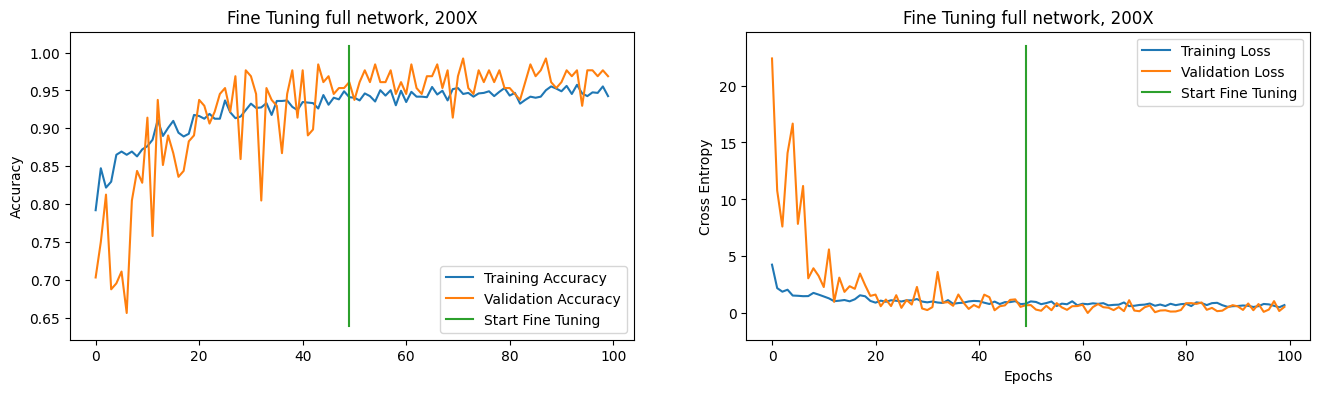

Resolutions:  75%|███████████████████▌      | 3/4 [4:20:05<1:26:33, 5193.25s/it]

Found 1820 files belonging to 2 classes.


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 28, 28,    │          0 │ conv2d_27[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_28[0][0],  │
│                     │                   │            │ conv2d_29[0][0],  │
│                     │                   │            │ max_pooling2d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_9[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 857,410 (3.27 MB)

 Trainable params: 524,034 (2.00 MB)

 Non-trainable params: 333,376 (1.27 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.
Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 825ms/step - accuracy: 0.7194 - loss: 4.1355
Epoch 1: val_accuracy improved from -inf to 0.82031, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v01/400X/model-weights.01-0.820312.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.7230 - loss: 4.1369 - val_accuracy: 0.8203 - val_loss: 3.9656
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 837ms/step - accuracy: 0.7923 - loss: 2.4117
Epoch 2: val_accuracy improved from 0.82031 to 0.88281, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v01/400X/model-weights.02-0.882812.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.7938 - loss: 2.4003 - val_accuracy: 0.8828 - val_loss: 2.0622
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 842ms/step - accuracy: 0.8093 - loss: 1.6256
Epoch 3: val_accuracy did not improve from 0.88281
10

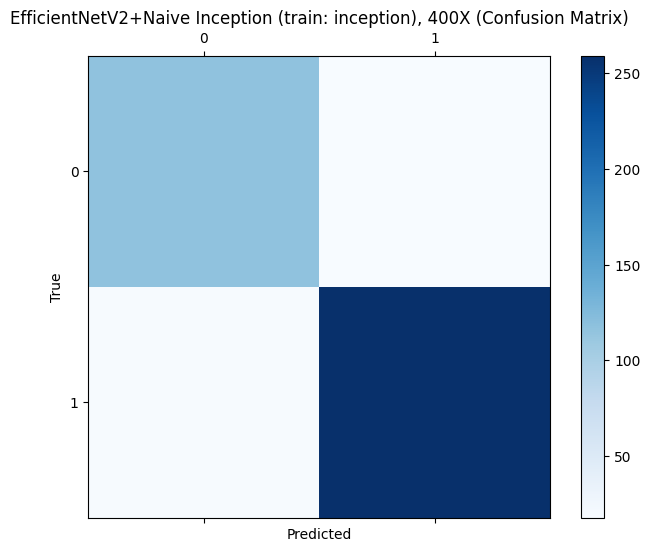

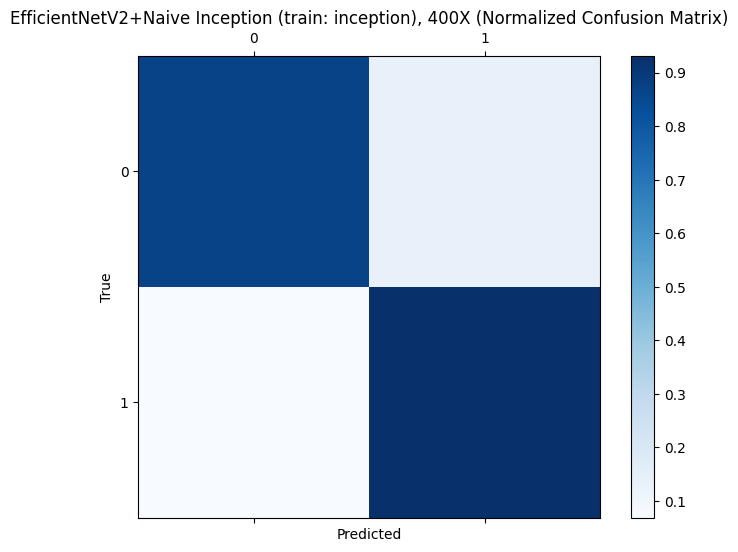

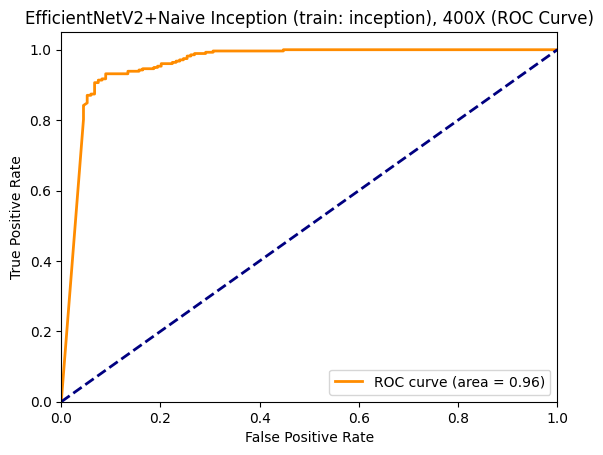

input_layer_23 False
rescaling_23 False
normalization_23 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv False
block1a_project_bn False
block1a_project_activation False
block1b_project_conv False
block1b_project_bn False
block1b_project_activation False
block1b_drop False
block1b_add False
block2a_expand_conv False
block2a_expand_bn False
block2a_expand_activation False
block2a_project_conv False
block2a_project_bn False
block2b_expand_conv False
block2b_expand_bn False
block2b_expand_activation False
block2b_project_conv False
block2b_project_bn False
block2b_drop False
block2b_add False
block2c_expand_conv False
block2c_expand_bn False
block2c_expand_activation False
block2c_project_conv False
block2c_project_bn False
block2c_drop False
block2c_add False
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 28, 28,    │          0 │ conv2d_27[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_28[0][0],  │
│                     │                   │            │ conv2d_29[0][0],  │
│                     │                   │            │ max_pooling2d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_9[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,905,480 (7.27 MB)

 Trainable params: 752,674 (2.87 MB)

 Non-trainable params: 104,736 (409.12 KB)

 Optimizer params: 1,048,070 (4.00 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8434 - loss: 3.2270
Epoch 51: val_accuracy improved from -inf to 0.75781, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v02/400X/model-weights.51-0.757812.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.8427 - loss: 3.2427 - val_accuracy: 0.7578 - val_loss: 4.1179 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8385 - loss: 3.1150
Epoch 52: val_accuracy improved from 0.75781 to 0.83594, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v02/400X/model-weights.52-0.835938.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.8369 - lo

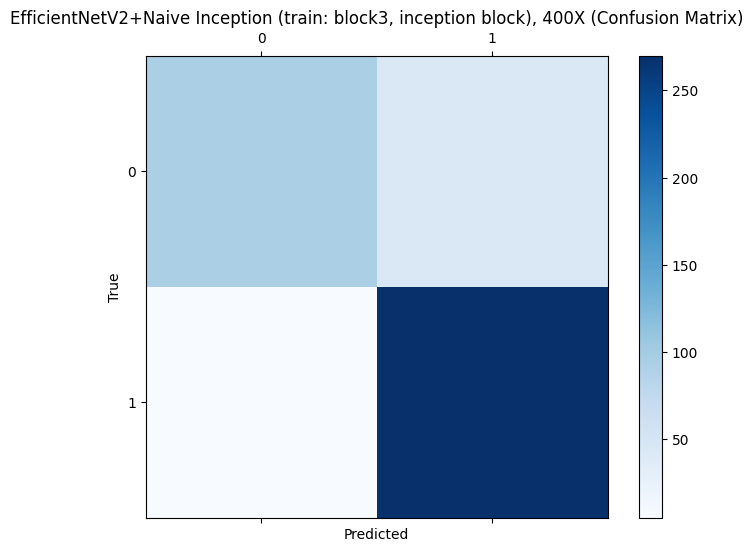

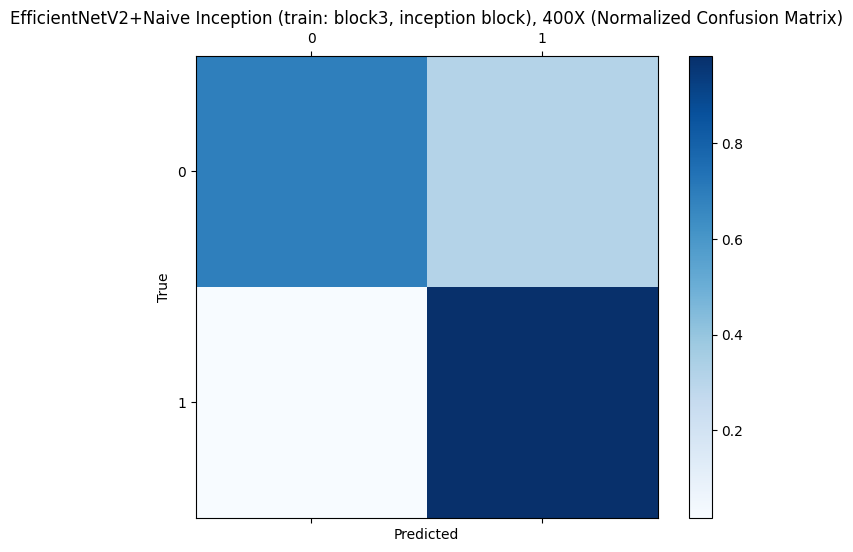

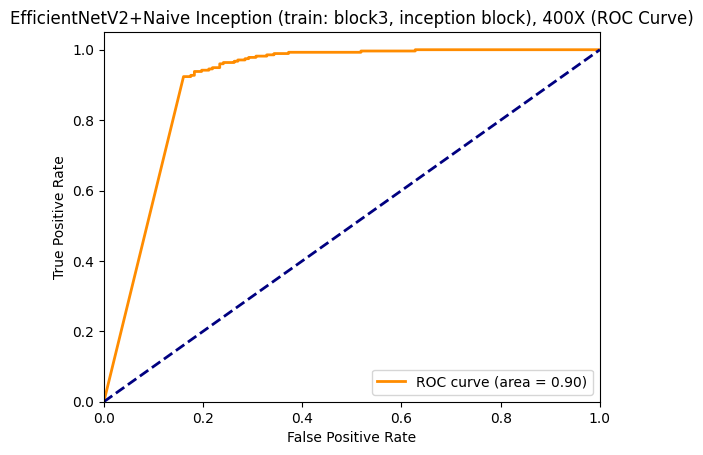

input_layer_23 False
rescaling_23 False
normalization_23 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv False
block1a_project_bn False
block1a_project_activation False
block1b_project_conv False
block1b_project_bn False
block1b_project_activation False
block1b_drop False
block1b_add False
block2a_expand_conv True
block2a_expand_bn True
block2a_expand_activation True
block2a_project_conv True
block2a_project_bn True
block2b_expand_conv True
block2b_expand_bn True
block2b_expand_activation True
block2b_project_conv True
block2b_project_bn True
block2b_drop True
block2b_add True
block2c_expand_conv True
block2c_expand_bn True
block2c_expand_activation True
block2c_project_conv True
block2c_project_bn True
block2c_drop True
block2c_add True
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation True
block3b_proje

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 28, 28,    │          0 │ conv2d_27[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_28[0][0],  │
│                     │                   │            │ conv2d_29[0][0],  │
│                     │                   │            │ max_pooling2d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_9[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,362,760 (9.01 MB)

 Trainable params: 846,690 (3.23 MB)

 Non-trainable params: 10,720 (41.88 KB)

 Optimizer params: 1,505,350 (5.74 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8565 - loss: 1.6565
Epoch 51: val_accuracy improved from -inf to 0.78125, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v03/400X/model-weights.51-0.781250.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 33s 3s/step - accuracy: 0.8557 - loss: 1.6798 - val_accuracy: 0.7812 - val_loss: 3.2533 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8503 - loss: 2.0388
Epoch 52: val_accuracy improved from 0.78125 to 0.83594, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v03/400X/model-weights.52-0.835938.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - accuracy: 0.8506 - lo

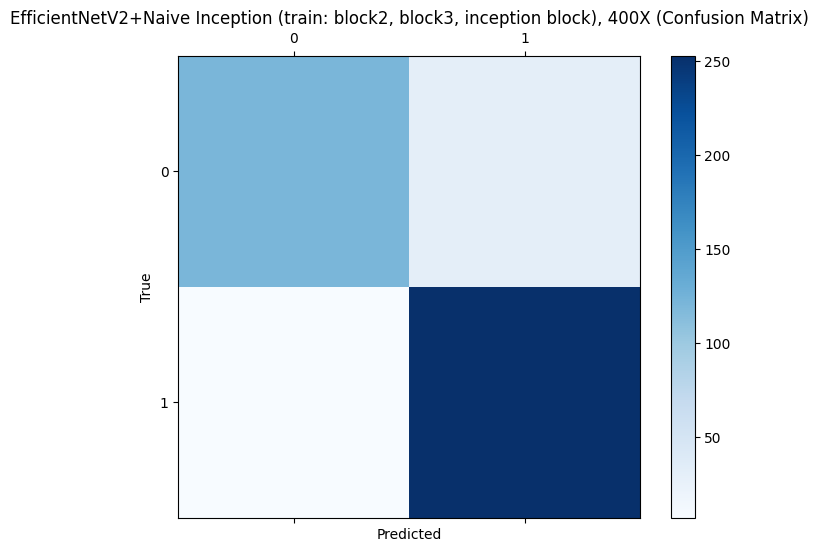

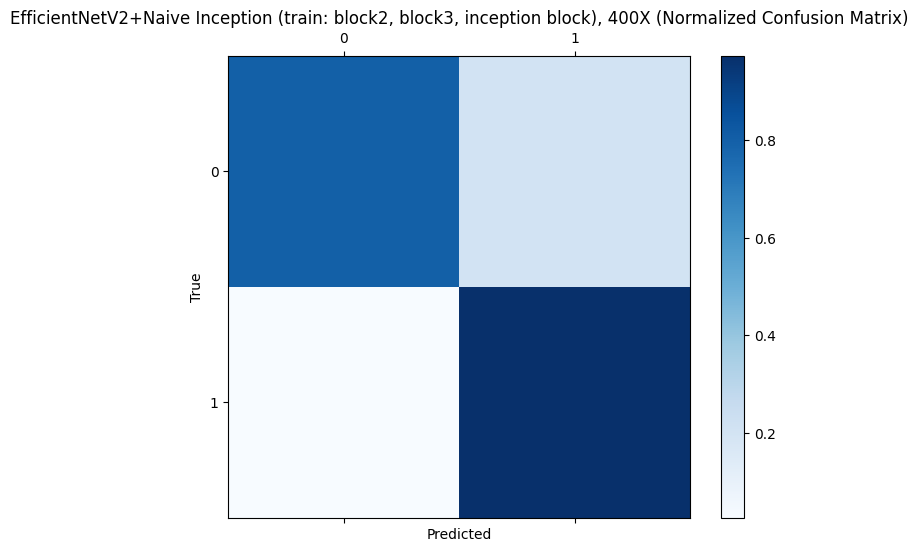

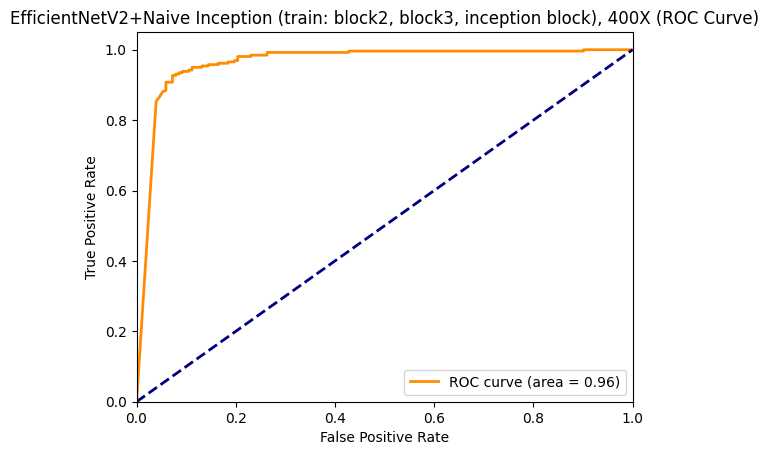

input_layer_23 False
rescaling_23 False
normalization_23 False
stem_conv False
stem_bn False
stem_activation False
block1a_project_conv True
block1a_project_bn True
block1a_project_activation True
block1b_project_conv True
block1b_project_bn True
block1b_project_activation True
block1b_drop True
block1b_add True
block2a_expand_conv True
block2a_expand_bn True
block2a_expand_activation True
block2a_project_conv True
block2a_project_bn True
block2b_expand_conv True
block2b_expand_bn True
block2b_expand_activation True
block2b_project_conv True
block2b_project_bn True
block2b_drop True
block2b_add True
block2c_expand_conv True
block2c_expand_bn True
block2c_expand_activation True
block2c_project_conv True
block2c_project_bn True
block2c_drop True
block2c_add True
block3a_expand_conv True
block3a_expand_bn True
block3a_expand_activation True
block3a_project_conv True
block3a_project_bn True
block3b_expand_conv True
block3b_expand_bn True
block3b_expand_activation True
block3b_project_conv 

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Image_Input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2b1_s… │ (None, 28, 28,    │    332,832 │ Image_Input[0][0] │
│ (Functional)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 28, 28,    │      3,136 │ efficientnetv2b1… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 28, 28,    │     55,424 │ efficientnetv2b1… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 28, 28,    │     38,432 │ efficientnetv2b1… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 28, 28,    │          0 │ efficientnetv2b1… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 28, 28,    │          0 │ conv2d_27[0][0],  │
│ (Concatenate)       │ 272)              │            │ conv2d_28[0][0],  │
│                     │                   │            │ conv2d_29[0][0],  │
│                     │                   │            │ max_pooling2d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ BN                  │ (None, 28, 28,    │      1,088 │ concatenate_9[0]… │
│ (BatchNormalizatio… │ 272)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 213248)    │          0 │ BN[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dropout (Dropout)   │ (None, 213248)    │          0 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Predictions (Dense) │ (None, 2)         │    426,498 │ Dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,550,792 (9.73 MB)

 Trainable params: 853,666 (3.26 MB)

 Non-trainable params: 3,744 (14.62 KB)

 Optimizer params: 1,693,382 (6.46 MB)

Nenhum checkpoint encontrado, iniciando novo treinamento.

Epoch 51: LearningRateScheduler setting learning rate to 1.0000571026483752e-05.
Epoch 51/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8808 - loss: 1.3840
Epoch 51: val_accuracy improved from -inf to 0.90625, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v04/400X/model-weights.51-0.906250.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 3s/step - accuracy: 0.8808 - loss: 1.3871 - val_accuracy: 0.9062 - val_loss: 1.2291 - learning_rate: 1.0001e-05

Epoch 52: LearningRateScheduler setting learning rate to 1.0000456720280865e-05.
Epoch 52/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8866 - loss: 1.6107
Epoch 52: val_accuracy improved from 0.90625 to 0.93750, saving model to /Users/flaviab/Downloads/data_breakhis/training_models_checkpoints/EfficientNetV2_Incept_v04/400X/model-weights.52-0.937500.keras
10/10 ━━━━━━━━━━━━━━━━━━━━ 35s 3s/step - accuracy: 0.8865 - lo

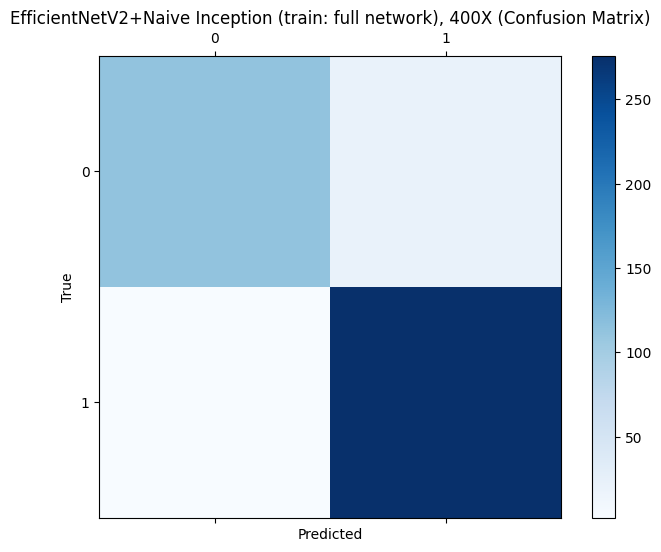

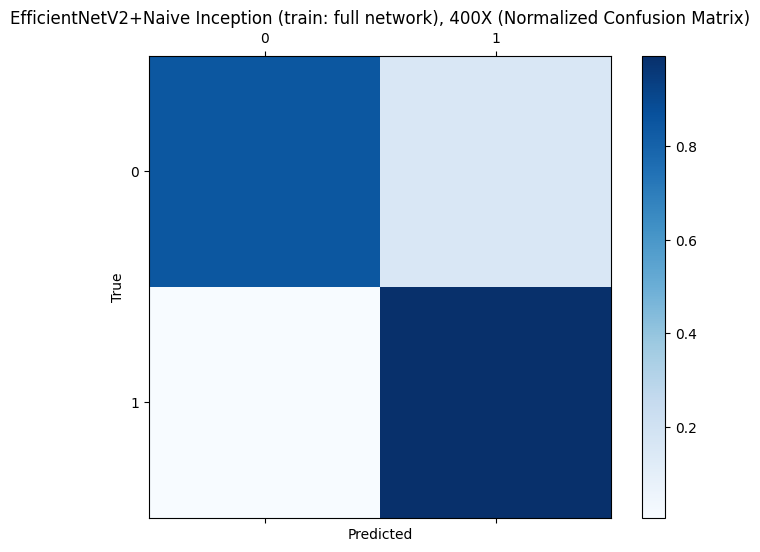

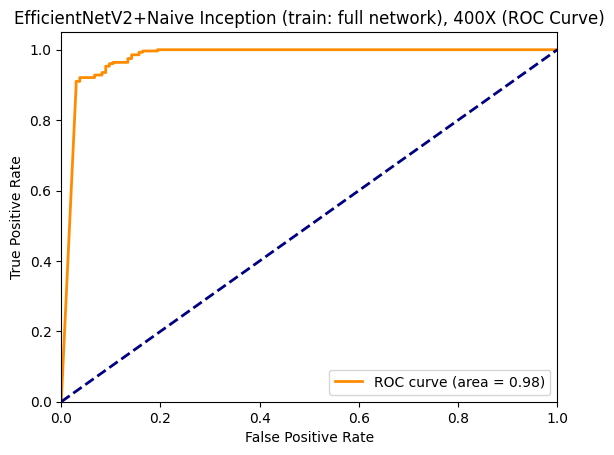

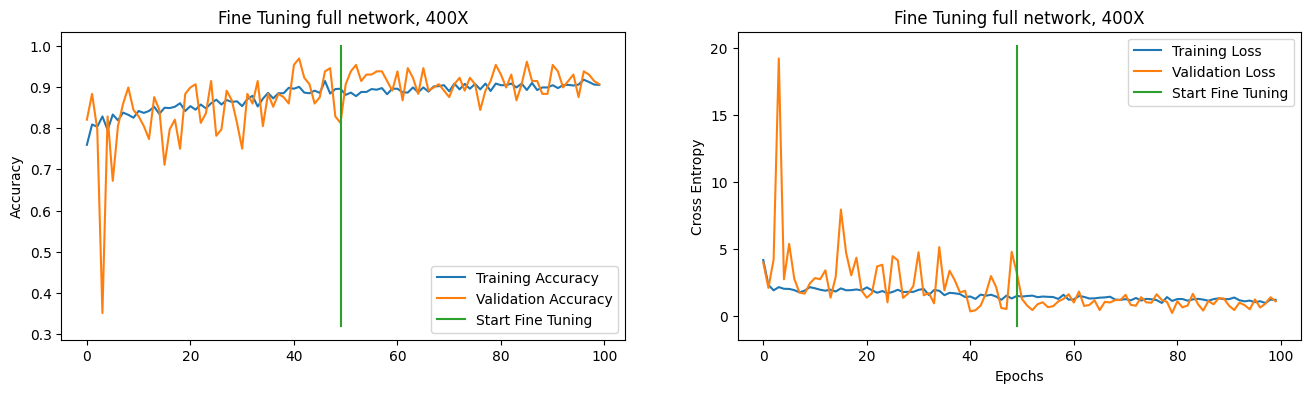

Resolutions: 100%|████████████████████████████| 4/4 [5:39:12<00:00, 5088.14s/it]


In [23]:
def process_model_for_resolution_efficientnetv2(resolution: str, iters: int = 50) -> None:
    
    """
    Função unificada para treinar e ajustar o modelo EfficientNetV2-b1 com um bloco Inception 
    baseado em diferentes resoluções de imagem.

    Parâmetros:
    - resolution (str): Resolução das imagens (por exemplo, '40', '100', '200', '400').
    - iters (int): Número de iterações (épocas) para o treinamento. O padrão é 50.

    Retorna:
    - None: Salva os modelos e pesos em cada etapa de treinamento e fine-tuning.
    """
    
    ds_path = f'/Users/flaviab/Downloads/data_breakhis/{resolution}X/'  
    train_data, val_data, test_data = dataset(ds_path)

    # 1. Treinamento do modelo base
    folder_initial = os.path.join(save_path, f"EfficientNetV2_Incept_v01/{resolution}X/")
    os.makedirs(folder_initial, exist_ok=True)

    model = efficientnetv2_builder() 
    model.summary()

    model = load_latest_checkpoint(folder_initial, model)

    checkpoint_path_initial = os.path.join(folder_initial, "model_initial_weights.{epoch:02d}-{val_accuracy:.6f}.keras")
    checkpoint_initial = ModelCheckpoint(filepath=checkpoint_path_initial, monitor='val_loss', save_best_only=True, save_weights_only=False)

    history_initial, model_initial = model_dataset_epoch(
        model, train_data, val_data, test_data, epoch=iters, 
        folder_path=folder_initial, strategy="train", 
        plot_title=f"EfficientNetV2+Naive Inception (train: inception), {resolution}X"
    )

    model_initial.save(os.path.join(folder_initial, f'model_initial_{resolution}X.h5'))

    # 2. Ajuste fino do Conv3 + Inception block
    folder_finetune_1 = os.path.join(save_path, f"EfficientNetV2_Incept_v02/{resolution}X/")
    os.makedirs(folder_finetune_1, exist_ok=True)

    model = efficientnetv2_builder(finetune=True, model=model_initial, trainable_blocks=['block3'], print_trainable=True)
    model.summary()

    model = load_latest_checkpoint(folder_finetune_1, model)

    checkpoint_path_finetune_1 = os.path.join(folder_finetune_1, "model_finetune_1_weights.{epoch:02d}-{val_accuracy:.6f}.keras")
    checkpoint_finetune_1 = ModelCheckpoint(filepath=checkpoint_path_finetune_1, monitor='val_loss', save_best_only=True, save_weights_only=False)

    history_finetune_1, model_finetune_1 = model_dataset_epoch(
        model, train_data, val_data, test_data, epoch=iters, 
        folder_path=folder_finetune_1, strategy="finetune", 
        plot_title=f"EfficientNetV2+Naive Inception (train: block3, inception block), {resolution}X"
    )

    model_finetune_1.save(os.path.join(folder_finetune_1, f'model_finetune_1_{resolution}X.h5'))

    # Fine-tuning 2
    folder_finetune_2 = os.path.join(save_path, f"EfficientNetV2_Incept_v03/{resolution}X/")
    os.makedirs(folder_finetune_2, exist_ok=True)

    model = efficientnetv2_builder(finetune=True, model=model_finetune_1, trainable_blocks=['block2', 'block3'], print_trainable=True)
    model.summary()

    model = load_latest_checkpoint(folder_finetune_2, model)

    checkpoint_path_finetune_2 = os.path.join(folder_finetune_2, "model_finetune_2_weights.{epoch:02d}-{val_accuracy:.6f}.keras")
    checkpoint_finetune_2 = ModelCheckpoint(filepath=checkpoint_path_finetune_2, monitor='val_loss', save_best_only=True, save_weights_only=False)

    history_finetune_2, model_finetune_2 = model_dataset_epoch(
        model, train_data, val_data, test_data, epoch=iters, 
        folder_path=folder_finetune_2, strategy="finetune", 
        plot_title=f"EfficientNetV2+Naive Inception (train: block2, block3, inception block), {resolution}X"
    )

    model_finetune_2.save(os.path.join(folder_finetune_2, f'model_finetune_2_{resolution}X.h5'))

    # Fine-tuning 3
    folder_finetune_3 = os.path.join(save_path, f"EfficientNetV2_Incept_v04/{resolution}X/")
    os.makedirs(folder_finetune_3, exist_ok=True)

    model = efficientnetv2_builder(finetune=True, model=model_finetune_2, trainable_blocks=['block1', 'block2', 'block3'], print_trainable=True)
    model.summary()

    model = load_latest_checkpoint(folder_finetune_3, model)

    checkpoint_path_finetune_3 = os.path.join(folder_finetune_3, "model_finetune_3_weights.{epoch:02d}-{val_accuracy:.6f}.keras")
    checkpoint_finetune_3 = ModelCheckpoint(filepath=checkpoint_path_finetune_3, monitor='val_loss', save_best_only=True, save_weights_only=False)

    history_finetune_3, model_finetune_3 = model_dataset_epoch(
        model, train_data, val_data, test_data, epoch=iters, 
        folder_path=folder_finetune_3, strategy="finetune", 
        plot_title=f"EfficientNetV2+Naive Inception (train: full network), {resolution}X"
    )

    model_finetune_3.save(os.path.join(folder_finetune_3, f'model_finetune_3_{resolution}X.h5'))

    model_finetune_3.save_weights(os.path.join(folder_finetune_3, f'model_finetune_3_weights_{resolution}X.weights.h5'))

    plot_train_history(history_initial, history_finetune_3, title=f"Fine Tuning full network, {resolution}X")


for resolution in tqdm(['40', '100', '200', '400'], desc="Resolutions"):
    process_model_for_resolution_efficientnetv2(resolution)

#### Artigo de Referência
Enhancing breast cancer classification via histopathological image analysis: Leveraging self-supervised contrastive learning and transfer learning

#### Repositório com referência de implementação
https://github.com/fbabd/Histopathological-image-breast-cancer-classification